<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-09/lab-048-spiking-reservoir.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning in Classical and Quantum Physics
2026/2027 <br>
**Author:** Marcin Płodzień <br>
**Lab:** 048 <br>
<hr/>

# Lab 048 — Spiking reservoir

A reservoir computer drives a fixed random dynamical system with the measured signal and trains only a linear readout of its state. The echo state network (ESN) uses tanh units that update once per sample. Real neurons communicate with short voltage pulses, the spikes, and a network of model neurons that emit spikes is a reservoir as well. Maass, Natschläger and Markram called such a network a liquid state machine (LSM), with the picture of a liquid whose surface keeps the ripples of everything thrown into it for a while [W. Maass, T. Natschläger, H. Markram, Neural Comput. **14**, 2531 (2002), [doi:10.1162/089976602760407955](https://doi.org/10.1162/089976602760407955)]. The picture is an analogy. The model itself is a set of coupled differential equations with a threshold.

The extra complexity of spikes pays off first on neuromorphic chips, which compute with spikes and on which a neuron uses energy only when it fires, so that a spiking reservoir with a trained readout is a natural program for them [M. Davies *et al.*, IEEE Micro **38**, 82 (2018), [doi:10.1109/MM.2018.112130359](https://doi.org/10.1109/MM.2018.112130359)]. Event-based sensors, such as event cameras, also deliver their data as streams of spikes in the first place [G. Gallego *et al.*, IEEE Trans. Pattern Anal. Mach. Intell. **44**, 154 (2022), [doi:10.1109/TPAMI.2020.3008413](https://doi.org/10.1109/TPAMI.2020.3008413)]. In neuroscience the LSM was proposed as a model of computation in cortical circuits, where the same question arises, how a fixed recurrent network of spiking cells can support many readouts [Maass, Natschläger, Markram (2002)].

We start with the physics of one model neuron, the leaky integrate-and-fire (LIF) neuron. Its membrane is an RC circuit, and solving the circuit equation shows that the voltage is an exponentially weighted history of the input current. A threshold and a reset turn this circuit into a source of spikes, and we compare the simulated firing rate with its analytic formula. The leak of the membrane turns out to be the continuous-time version of the leak rate of the ESN. We then build a random network of 300 LIF neurons, drive it with the benchmark signals, look at its spikes, test whether its state forgets the initial condition, measure its memory capacity and forecast the Lorenz-63, Mackey–Glass and Santa Fe signals with the same protocol and scores as the autoregressive (AR), nonlinear vector autoregressive (NVAR) and ESN models. A short last part shows why spiking networks cannot be trained by plain gradient descent and how surrogate gradients get around this.

The LIF implementation in JAX uses the explicit Euler method with a time step much shorter than every time constant of the model. The network simulation runs in single precision, and all regressions in double precision.

> **Running this notebook in Google Colab**
> 1. Go to <https://colab.research.google.com> and choose *File, Upload notebook*. The first code cell sets `JAX_PLATFORMS=cpu`. The recorded run of the whole notebook took 7 minutes on a multi-core CPU that was shared with other jobs.
> 2. `jax`, `scikit-learn` and `matplotlib` are pre-installed in Colab.
> 3. The first code cell downloads the data file into a folder `data` next to the notebook. It is the data set A of the Santa Fe time-series competition, distributed with the notebooks on recurrent networks.
> 4. Optionally upload `numbers_lab046.json`, written by the notebook on echo state networks. With it the forecasting section compares its reference scores with the values recomputed here. Without it this comparison is skipped.
> 5. Run the cells in order. Later cells use variables defined earlier.

In [ ]:
# data files of this notebook, downloaded from the course repository if they are not in ./data
import os, urllib.request
os.makedirs("data", exist_ok=True)
for name in ['santafe_laser.txt']:
    if not os.path.exists(f"data/{name}"):
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/main/notebooks/lecture-09/data/{name}", f"data/{name}")

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"     # run JAX on the CPU (set before importing jax)

import json, time, itertools
from functools import partial
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Ellipse, Rectangle, FancyBboxPatch

import jax, jax.numpy as jnp
jax.config.update("jax_enable_x64", True)   # double precision by default; the network simulation casts to float32
import sklearn
from sklearn.linear_model import Ridge as SkRidge

# common style of the notebook figures
mpl.rcParams.update({"font.size": 14, "axes.labelsize": 15, "axes.titlesize": 15,
                     "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 12,
                     "figure.titlesize": 16, "lines.linewidth": 2.0,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})
# slide figures are drawn at their printed size (5.5 in = full width of a slide), so these are true font sizes
SLIDE_RC = {"font.size": 11, "axes.labelsize": 11, "axes.titlesize": 11, "xtick.labelsize": 11,
            "ytick.labelsize": 11, "legend.fontsize": 11, "lines.linewidth": 1.4, "figure.dpi": 150}

UJBlue, UJNavy, DSOrange, UJGray = "#005CA7", "#002B5C", "#D35A05", "#5A6270"
Teal, INH = "#2A9D8F", "#C44E52"          # INH: colour of the inhibitory neurons in every figure
# one colour and line style per model, used in every figure
STYLE = {"persistence": dict(color="0.55", ls=":"), "AR": dict(color="0.35", ls="--"),
         "NVAR": dict(color=DSOrange, ls="--"), "ESN": dict(color=UJBlue, ls="-"),
         "LSM": dict(color=Teal, ls="-")}

OUT = "figures"
os.makedirs(OUT, exist_ok=True)
from matplotlib.lines import Line2D
def model_legend(ax, models, **kw):
    # legend built from the line styles of STYLE, so that every swatch has the colour of its curve
    ax.legend([Line2D([], [], lw=1.6, **STYLE[m]) for m in models], models, **kw)

def find_file(name, *extra):
    # look next to the notebook first, then in the usual subfolders and in the given folders
    for d in ("", "data", "figures") + extra:
        p = os.path.join(d, name)
        if os.path.exists(p):
            return p
    return None

def save(fig, name):
    # slide figures are created at their printed size and saved as PDF (slides) and PNG
    for ext in ("pdf", "png"):
        fig.savefig(f"{OUT}/{name}.{ext}", dpi=300, bbox_inches="tight", pad_inches=0.02)

nums = {}                 # every number a slide may need, written to the numbers file at the end
t_start = time.time()
print("jax", jax.__version__, "| scikit-learn", sklearn.__version__)

jax 0.11.0 | scikit-learn 1.6.1


<hr/>
## 1. The leaky integrate-and-fire neuron

### The membrane as an RC circuit

The membrane of a nerve cell is a thin lipid layer that separates two conducting salt solutions. It stores charge like a capacitor of capacitance $C_m$, and ion channels let a small current leak through it like a resistor $R$. Ion pumps keep the inside at a resting potential $V_{\rm rest}$ relative to the outside when no current is injected, which in the circuit is a battery in series with the resistor. Lapicque modelled the nerve membrane by this circuit in 1907 [L. Lapicque, J. Physiol. Pathol. Gén. **9**, 620 (1907); L. F. Abbott, Brain Res. Bull. **50**, 303 (1999), [doi:10.1016/S0361-9230(99)00161-6](https://doi.org/10.1016/S0361-9230(99)00161-6)]. A current $I(t)$ injected into the cell splits into the charging current of the capacitor and the leak current through the resistor,
$$I(t)=C_m\,\frac{dV}{dt}+\frac{V-V_{\rm rest}}{R}.$$
Multiplying by $R$ and defining the membrane time constant $\tau_m=RC_m$ gives the equation of the LIF neuron below threshold,
$$\tau_m\frac{dV}{dt}=-(V-V_{\rm rest})+R\,I(t).$$
We use the illustrative values $\tau_m=20$ ms and $R=100$ M$\Omega$, so $C_m=\tau_m/R=0.2$ nF. With currents in nA the product $RI$ is in mV. The drawing shows the circuit. The comparator on the right is the threshold rule added further below. It is the only element that the passive circuit lacks.

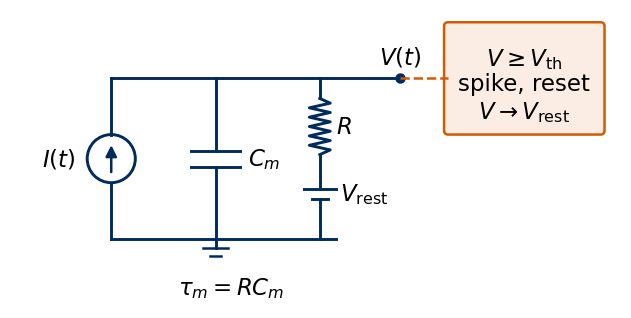

In [2]:
def zigzag(ax, x, y0, y1, n=6, w=0.13, **kw):
    # vertical resistor symbol between heights y0 and y1 at position x
    ys = np.linspace(y0, y1, 2 * n + 1)
    xs = x + w * np.r_[0, np.tile([1, -1], n)[:2 * n - 1], 0]
    ax.plot(xs, ys, **kw)

with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(5.5, 2.5))
    k = dict(color=UJNavy, lw=1.4)
    yb, yt = 0.0, 2.0
    ax.plot([0.6, 4.2], [yt, yt], **k); ax.plot([0.6, 3.4], [yb, yb], **k)            # top node V, ground
    # current source I(t)
    ax.plot([0.6, 0.6], [yb, 0.7], **k); ax.plot([0.6, 0.6], [1.3, yt], **k)
    ax.add_patch(Circle((0.6, 1.0), 0.3, fc="white", ec=UJNavy, lw=1.4))
    ax.annotate("", xy=(0.6, 1.22), xytext=(0.6, 0.78), arrowprops=dict(arrowstyle="-|>", color=UJNavy, lw=1.2))
    ax.text(0.15, 1.0, r"$I(t)$", ha="right", va="center")
    # capacitor C_m
    ax.plot([1.9, 1.9], [yt, 1.1], **k); ax.plot([1.9, 1.9], [0.9, yb], **k)
    ax.plot([1.6, 2.2], [1.1, 1.1], **k); ax.plot([1.6, 2.2], [0.9, 0.9], **k)
    ax.text(2.3, 1.0, r"$C_m$", ha="left", va="center")
    # leak resistor R in series with the resting-potential battery
    ax.plot([3.2, 3.2], [yt, 1.75], **k); zigzag(ax, 3.2, 1.75, 1.05, **k)
    ax.plot([3.2, 3.2], [1.05, 0.62], **k)
    ax.plot([3.0, 3.4], [0.62, 0.62], **k); ax.plot([3.1, 3.3], [0.5, 0.5], **k)
    ax.plot([3.2, 3.2], [0.5, yb], **k)
    ax.text(3.4, 1.4, r"$R$", ha="left", va="center"); ax.text(3.45, 0.56, r"$V_{\rm rest}$", ha="left", va="center")
    ax.plot([3.4, 3.4], [yb, yb], **k)
    # ground and node label
    ax.plot([1.75, 2.05], [-0.12, -0.12], color=UJNavy, lw=1.2); ax.plot([1.83, 1.97], [-0.22, -0.22], color=UJNavy, lw=1.2)
    ax.plot([1.9, 1.9], [yb, -0.12], **k)
    ax.plot(4.2, yt, "o", color=UJNavy, ms=4); ax.text(4.2, yt + 0.12, r"$V(t)$", ha="center", va="bottom")
    # threshold rule
    ax.plot([4.2, 4.8], [yt, yt], color=DSOrange, lw=1.2, ls="--")
    ax.add_patch(FancyBboxPatch((4.8, 1.35), 1.9, 1.3, boxstyle="round,pad=0.05", fc="#FBEDE3", ec=DSOrange, lw=1.2))
    ax.text(5.75, 2.25, r"$V\geq V_{\rm th}$", ha="center", va="center")
    ax.text(5.75, 1.75, "spike, reset\n" + r"$V\to V_{\rm rest}$", ha="center", va="center")
    ax.text(2.1, -0.45, r"$\tau_m=RC_m$", ha="center", va="top")
    ax.set_xlim(-0.6, 6.9); ax.set_ylim(-0.8, 2.8); ax.set_aspect("equal"); ax.axis("off")
    save(fig, "fig_lab048_rc_circuit"); plt.show()

### Relaxation and the exponential kernel

We write $v=V-V_{\rm rest}$ for the voltage above rest, so that $\tau_m\dot v=-v+RI(t)$. Without input the deviation relaxes as $v(t)=v(0)e^{-t/\tau_m}$, and after one time constant 37% of it is left. For a constant current $I_0$ switched on at $t=0$ the voltage approaches the equilibrium $v_\infty=RI_0$,
$$v(t)=v_\infty+\big(v(0)-v_\infty\big)e^{-t/\tau_m}.$$
For a general input we multiply the equation by $e^{t/\tau_m}$. The left-hand side becomes a total derivative, $\tau_m\,\frac{d}{dt}\big(v\,e^{t/\tau_m}\big)=R\,I(t)\,e^{t/\tau_m}$, and integration from 0 to $t$ gives
$$v(t)=v(0)\,e^{-t/\tau_m}+\int_0^t\kappa(t-t')\,I(t')\,dt',\qquad \kappa(s)=\frac{R}{\tau_m}\,e^{-s/\tau_m}.$$
The voltage is a convolution of the input current with an exponential kernel $\kappa$. An input that arrived a time $s$ ago enters with the weight $e^{-s/\tau_m}$, so the state is an exponentially weighted history of the input. Both the initial condition and old inputs are therefore forgotten exponentially, the two kinds of forgetting that a reservoir needs and that are defined further below.

We integrate the equation with the explicit Euler method, $v_{n+1}=v_n+\frac{\Delta t}{\tau_m}\big(-v_n+RI_n\big)$, with $\Delta t=0.05$ ms and the Euler step $n$. The left panel compares the simulated response to two current steps (circles) with the analytic solution (lines), and the dotted line marks the threshold $v_{\rm th}=15$ mV of the spiking neuron introduced below. The right panels drive the circuit with a random current made of five sinusoids and compare the Euler solution (blue) with the convolution integral evaluated as a sum over the same grid (dashed orange). The largest deviation from the analytic step response is $1.2\times10^{-2}$ mV and from the convolution $2.0\times10^{-2}$ mV, both far below the equilibrium voltages $RI_0=10$ mV and 25 mV of the two steps.

max |Euler - analytic| for the steps: 1.2e-02 mV, max |Euler - convolution|: 2.0e-02 mV


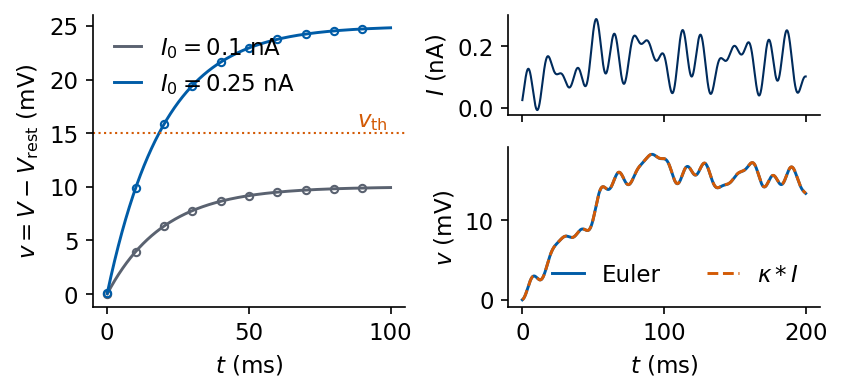

In [3]:
TAU_M, R_M, V_TH, T_REF1 = 20.0, 100.0, 15.0, 2.0     # ms, MOhm, threshold in mV above rest, refractory time in ms
DT1 = 0.05                                             # Euler step of the single-neuron simulations (ms)
nums["lif"] = dict(tau_m=TAU_M, R=R_M, C_nF=TAU_M / R_M, v_th=V_TH, dt=DT1, rheobase_nA=V_TH / R_M)

@partial(jax.jit, static_argnames=("spiking", "t_ref"))
def lif_euler(I, spiking=True, t_ref=T_REF1, tau=TAU_M, R=R_M, v_th=V_TH, dt=DT1):
    # v = V - V_rest (mV) driven by the current I (nA) on a grid of step dt; returns v before reset and spike flags
    n_ref = int(round(t_ref / dt))                     # refractory time in Euler steps
    def step(carry, Ik):
        v, ref = carry
        v = v + dt / tau * (-v + R * Ik)
        v = jnp.where(ref > 0, 0.0, v)                 # clamped at rest during the refractory time
        ref = jnp.maximum(ref - 1, 0)
        spk = (v >= v_th) & spiking
        v_out = v
        v = jnp.where(spk, 0.0, v)                     # reset to rest
        ref = jnp.where(spk, n_ref, ref)
        return (v, ref), (v_out, spk)
    _, (v, s) = jax.lax.scan(step, (jnp.zeros(()), jnp.zeros((), jnp.int32)), I)
    return v, s

t1 = DT1 * np.arange(1, int(100 / DT1) + 1)             # times t_n = n dt of the Euler states
step_dev, steps = 0.0, {}
for I0 in (0.10, 0.25):
    v, _ = lif_euler(jnp.full(len(t1), I0), spiking=False)
    steps[I0] = np.asarray(v)
    step_dev = max(step_dev, np.abs(steps[I0] - R_M * I0 * (1 - np.exp(-t1 / TAU_M))).max())

# random current: five sinusoids with random frequencies (up to 100 Hz) and phases around 0.15 nA
rng = np.random.default_rng(0)
t2 = DT1 * np.arange(int(200 / DT1))
fr, ph = rng.uniform(5, 100, 5), rng.uniform(0, 2 * np.pi, 5)
I_rand = 0.15 + 0.1 * np.sin(2 * np.pi * fr[None, :] * t2[:, None] / 1000 + ph[None, :]).sum(1) / np.sqrt(5)
v_euler = np.asarray(lif_euler(jnp.asarray(I_rand), spiking=False)[0])
kappa = R_M / TAU_M * np.exp(-t2 / TAU_M)                # kernel kappa(s) on the grid
v_conv = DT1 * np.convolve(I_rand, kappa)[:len(t2)]      # v(t_{n+1}) = dt sum_m kappa(t_n - t_m) I_m
conv_dev = np.abs(v_euler - v_conv).max()
nums["lif"].update(step_max_dev=float(step_dev), conv_max_dev=float(conv_dev))
print(f"max |Euler - analytic| for the steps: {step_dev:.1e} mV, max |Euler - convolution|: {conv_dev:.1e} mV")

with mpl.rc_context(SLIDE_RC):
    fig = plt.figure(figsize=(5.5, 2.5), layout="constrained")
    gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.6])
    ax = fig.add_subplot(gs[:, 0])
    for I0, c in ((0.10, UJGray), (0.25, UJBlue)):
        ax.plot(t1, R_M * I0 * (1 - np.exp(-t1 / TAU_M)), color=c, label=rf"$I_0={I0}$ nA")
        ax.plot(t1[::200], steps[I0][::200], "o", ms=3.5, mfc="none", color=c)
    ax.axhline(V_TH, color=DSOrange, ls=":", lw=1.0); ax.text(99, V_TH + 0.6, r"$v_{\rm th}$", ha="right", color=DSOrange)
    ax.set_xlabel("$t$ (ms)"); ax.set_ylabel("$v=V-V_{\\rm rest}$ (mV)"); ax.legend(loc="upper left", handlelength=1.2)
    a1 = fig.add_subplot(gs[0, 1]); a2 = fig.add_subplot(gs[1, 1], sharex=a1)
    a1.plot(t2, I_rand, color=UJNavy, lw=1.0); a1.set_ylabel("$I$ (nA)"); plt.setp(a1.get_xticklabels(), visible=False)
    a2.plot(t2, v_euler, color=UJBlue, label="Euler"); a2.plot(t2, v_conv, "--", color=DSOrange, label=r"$\kappa * I$")
    a2.set_xlabel("$t$ (ms)"); a2.set_ylabel("$v$ (mV)"); a2.legend(loc="lower right", ncol=2, handlelength=1.4)
    save(fig, "fig_lab048_relaxation"); plt.show()

### Threshold, reset and spikes

The passive circuit relaxes to $RI_0$ and stays there. The LIF model adds one rule that is foreign to the circuit. When $v$ reaches the threshold $v_{\rm th}=V_{\rm th}-V_{\rm rest}$, here 15 mV, the neuron emits a spike at that time, and $v$ is reset to zero. After a spike the voltage can be held at rest for a refractory time $t_{\rm ref}$, here 2 ms. Between spikes the circuit equation holds, and at a spike the state jumps, so the LIF neuron is a hybrid dynamical system. The spike itself carries no waveform in the model. Only its time matters.

For a constant current the neuron fires only if the equilibrium lies above threshold, $RI_0>v_{\rm th}$, that is, above the rheobase current $I_{\rm rh}=v_{\rm th}/R=0.15$ nA. From the reset value $v=0$ the solution $v(t)=RI_0(1-e^{-t/\tau_m})$ reaches the threshold after
$$T(I_0)=\tau_m\ln\frac{RI_0}{RI_0-v_{\rm th}},$$
and the firing rate is
$$\nu(I_0)=\frac{1}{t_{\rm ref}+T(I_0)}\quad(I_0>I_{\rm rh}),\qquad \nu(I_0)=0\quad(I_0\le I_{\rm rh}).$$
The figure shows the current step $I_0=0.25$ nA between 10 and 90 ms, the voltage with the threshold (dashed) and the spike times. The first spike appears 18.35 ms after the onset of the current, and the formula gives $T=\tau_m\ln 2.5=18.33$ ms. The difference is set by the Euler step.

first spike 18.35 ms after the onset, analytic T = 18.33 ms, 4 spikes in 80 ms


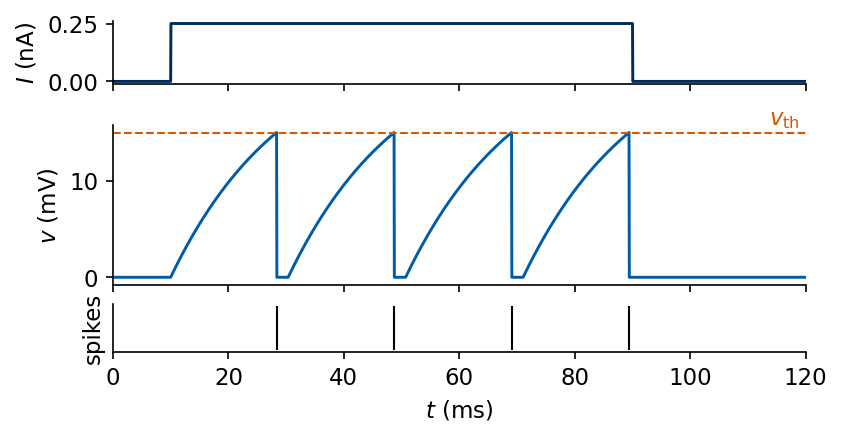

In [4]:
t3 = DT1 * np.arange(1, int(120 / DT1) + 1)
I_step = np.where((t3 > 10) & (t3 <= 90), 0.25, 0.0)
v3, s3 = (np.asarray(a) for a in lif_euler(jnp.asarray(I_step)))
t_spk = t3[s3]
T_exact = TAU_M * np.log(R_M * 0.25 / (R_M * 0.25 - V_TH))
nums["lif"].update(first_spike=float(t_spk[0] - 10), first_spike_exact=float(T_exact), n_spikes_step=int(s3.sum()))
print(f"first spike {t_spk[0] - 10:.2f} ms after the onset, analytic T = {T_exact:.2f} ms, {s3.sum()} spikes in 80 ms")

with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(3, 1, figsize=(5.5, 2.8), sharex=True, layout="constrained",
                            gridspec_kw={"height_ratios": [0.8, 2, 0.6]})
    axs[0].plot(t3, I_step, color=UJNavy); axs[0].set_ylabel("$I$ (nA)")
    axs[1].plot(t3, v3, color=UJBlue); axs[1].axhline(V_TH, color=DSOrange, ls="--", lw=1.0)
    axs[1].set_ylabel("$v$ (mV)"); axs[1].text(119, V_TH + 0.8, r"$v_{\rm th}$", ha="right", color=DSOrange)
    axs[2].vlines(t_spk, 0, 1, color="k", lw=1.0); axs[2].set_yticks([]); axs[2].set_ylabel("spikes")
    axs[2].set_xlabel("$t$ (ms)"); axs[2].set_xlim(0, 120)
    save(fig, "fig_lab048_lif_trace"); plt.show()

The firing-rate curve $\nu(I_0)$ is the response function of the neuron. We simulate one second for every current on a grid from 0 to 0.6 nA, measure the rate as the inverse of the mean interval between successive spikes, and compare it with the formula for $t_{\rm ref}=0$ and $t_{\rm ref}=2$ ms. Below the rheobase the neuron is silent, and above it fires periodically. Close to the rheobase the rate rises steeply, since $T(I_0)$ diverges logarithmically for $I_0\to I_{\rm rh}$, and for large currents it grows linearly without refractory time, $\nu\approx RI_0/(v_{\rm th}\tau_m)$, and saturates at $1/t_{\rm ref}$ with it. The largest relative deviation between simulation and formula over the currents with at least ten spikes per second is 0.6%, and it comes from the Euler discretisation and from the time grid, on which every threshold crossing is detected at the next Euler step.

largest relative deviation of the simulated rate from the formula (rates >= 10 Hz): 0.63%


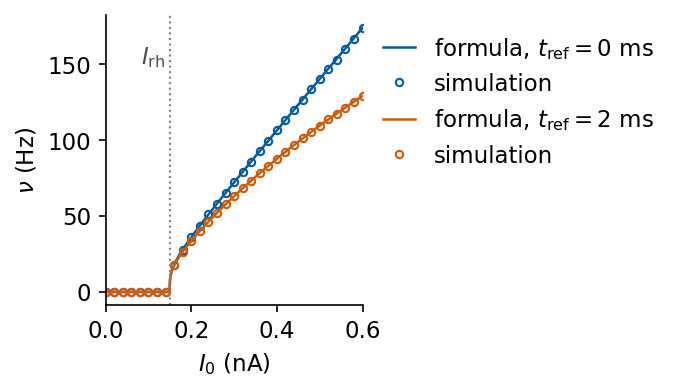

In [5]:
I_grid = np.round(np.arange(0.0, 0.601, 0.01), 3)
t4 = DT1 * np.arange(1, int(1000 / DT1) + 1)

def nu_lif(I0, t_ref, tau=TAU_M, R=R_M, v_th=V_TH):
    # analytic firing rate nu (Hz) for a constant current I0 (nA); zero at and below the rheobase
    I0 = np.asarray(I0, float)
    above = R * I0 > v_th
    T = np.full(I0.shape, np.inf)
    T[above] = tau * np.log(R * I0[above] / (R * I0[above] - v_th))
    return 1000.0 / (t_ref + T)

rates, fI_dev = {}, 0.0
for t_ref in (0.0, 2.0):
    S = np.asarray(jax.vmap(lambda I0: lif_euler(jnp.full(len(t4), I0), t_ref=t_ref)[1])(jnp.asarray(I_grid)))
    r = np.zeros(len(I_grid))
    for i, row in enumerate(S):
        ts = t4[row]
        r[i] = 1000.0 / np.diff(ts).mean() if len(ts) > 1 else 0.0     # inverse mean inter-spike interval (Hz)
    rates[t_ref] = r
    ok = nu_lif(I_grid, t_ref) >= 10
    fI_dev = max(fI_dev, np.abs(r[ok] / nu_lif(I_grid, t_ref)[ok] - 1).max())
nums["lif"]["fI_max_rel_dev"] = float(fI_dev)
print(f"largest relative deviation of the simulated rate from the formula (rates >= 10 Hz): {100 * fI_dev:.2f}%")

with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(4.4, 2.5), layout="constrained")
    Ifine = np.linspace(0, 0.6, 600)
    for t_ref, c in ((0.0, UJBlue), (2.0, DSOrange)):
        ax.plot(Ifine, nu_lif(Ifine, t_ref), color=c, lw=1.2, label=rf"formula, $t_{{\rm ref}}={t_ref:g}$ ms")
        ax.plot(I_grid[::2], rates[t_ref][::2], "o", ms=3.5, mfc="none", color=c, label="simulation")
    ax.axvline(V_TH / R_M, color="0.5", ls=":", lw=1.0)
    ax.text(V_TH / R_M - 0.01, 150, r"$I_{\rm rh}$", ha="right", color="0.3")
    ax.set_xlabel("$I_0$ (nA)"); ax.set_ylabel(r"$\nu$ (Hz)"); ax.set_xlim(0, 0.6)
    ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), handlelength=1.4)
    save(fig, "fig_lab048_fI"); plt.show()

### The membrane leak and the ESN leak rate

One Euler step of the membrane equation can be written as
$$v_{n+1}=(1-\alpha)\,v_n+\alpha\,RI_n,\qquad \alpha=\frac{\Delta t}{\tau_m}.$$
This is the update of the leaky ESN, $\mathbf r_k=(1-\alpha)\mathbf r_{k-1}+\alpha\tanh(W\mathbf r_{k-1}+\mathbf w_{\rm in}s_k)$, for one unit with the tanh replaced by the identity and with the recurrent input missing. The leak rate $\alpha$ of the ESN is the ratio of the time step to the relaxation time of a unit, and $\alpha=1$ means that a unit forgets its previous state within one step. With the recurrence the linearised ESN forgets by the factor $(1-\alpha)+\alpha\rho$ per step, where $\rho$ is the spectral radius, so a small leak rate lengthens its memory. Integrating the circuit exactly over a step with constant current gives $\alpha=1-e^{-\Delta t/\tau_m}$, which agrees with $\Delta t/\tau_m$ to first order. The LIF neuron keeps this linear leak and puts the nonlinearity into the threshold and the reset.

The network below uses the Euler step $\Delta t=0.5$ ms, so its $\alpha$ is a leak per Euler step. One input sample lasts 10 ms, 20 Euler steps, and without input the voltage keeps the fraction $(1-\alpha)^{20}$ over one sample. The leak per sample, $\alpha_{\rm sample}=1-(1-\alpha)^{20}\approx1-e^{-10\,{\rm ms}/\tau_m}$, is the quantity to compare with the leak rates $\alpha\in\{0.3,1\}$ of the ESN, which update once per sample. The output of the next cell gives both quantities for $\tau_m=5$, 10 and 20 ms.

In [6]:
nums["leak_per_sample"] = {}
for tm in (5.0, 10.0, 20.0):
    a = 0.5 / tm
    nums["leak_per_sample"][f"{tm:g}"] = 1 - (1 - a) ** 20
    print(f"tau_m = {tm:4.0f} ms: alpha = dt/tau_m = {a:.3f} per Euler step, 1 - exp(-dt/tau_m) = {1 - np.exp(-0.5 / tm):.4f},"
          f" retained after one 10 ms sample (1 - alpha)^20 = {(1 - a) ** 20:.3f},"
          f" leak per sample 1 - (1 - alpha)^20 = {1 - (1 - a) ** 20:.3f}")

tau_m =    5 ms: alpha = dt/tau_m = 0.100 per Euler step, 1 - exp(-dt/tau_m) = 0.0952, retained after one 10 ms sample (1 - alpha)^20 = 0.122, leak per sample 1 - (1 - alpha)^20 = 0.878
tau_m =   10 ms: alpha = dt/tau_m = 0.050 per Euler step, 1 - exp(-dt/tau_m) = 0.0488, retained after one 10 ms sample (1 - alpha)^20 = 0.358, leak per sample 1 - (1 - alpha)^20 = 0.642
tau_m =   20 ms: alpha = dt/tau_m = 0.025 per Euler step, 1 - exp(-dt/tau_m) = 0.0247, retained after one 10 ms sample (1 - alpha)^20 = 0.603, leak per sample 1 - (1 - alpha)^20 = 0.397


### Leak, integrator and memoryless unit

The leak is the term $-v$ on the right-hand side of the membrane equation. It removes a fixed fraction of the state per unit time, whatever the input does, and the loss is proportional to the present value of the state. Three units driven by the same train of input pulses $g_k$ show what this term does, with the time step $k$. A pure integrator, $x_k=x_{k-1}+\alpha g_k$, has no leak and adds up all past inputs. A leaky unit, $x_k=(1-\alpha)x_{k-1}+\alpha g_k$, keeps the fraction $1-\alpha$ of its value at every step. A memoryless unit, $x_k=g_k$, only copies the present input. We use $\alpha=0.1$, so the leaky unit has a memory time of about $1/\alpha=10$ steps.

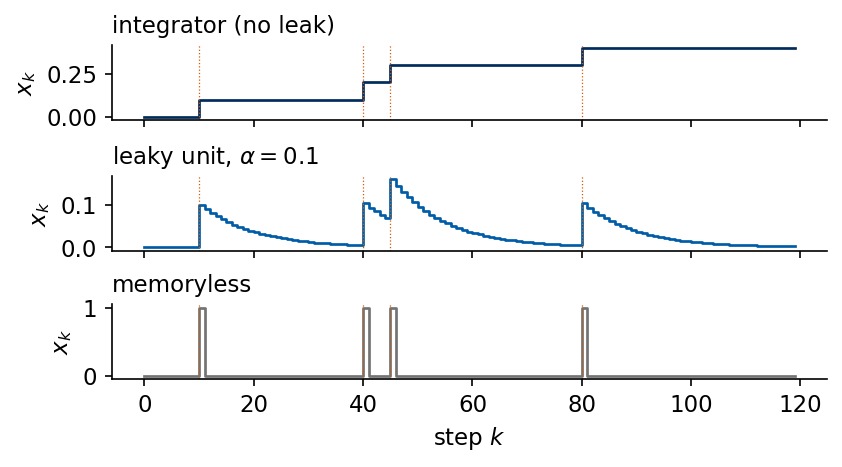

after the last pulse: integrator stays at 0.40; leaky unit falls from 0.104 to 0.0017 in 39 steps, ratio 0.0164 = (1 - alpha)^39 = 0.0164


In [7]:
# the same input pulses through a pure integrator, a leaky unit and a memoryless unit
ALPHA_L = 0.1
n_steps = 120                                            # time steps k = 0..119
g = np.zeros(n_steps); g[[10, 40, 45, 80]] = 1.0        # four unit pulses
x_int, x_leak = np.zeros(n_steps), np.zeros(n_steps)
for k in range(1, n_steps):
    x_int[k] = x_int[k - 1] + ALPHA_L * g[k]                       # no leak: sums every past input
    x_leak[k] = (1 - ALPHA_L) * x_leak[k - 1] + ALPHA_L * g[k]     # leak: keeps 1 - alpha per step
x_mem = g.copy()                                                    # no memory: copies the input
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(3, 1, figsize=(5.5, 3.0), layout="constrained", sharex=True)
    for ax, x, lab, col in zip(axs, (x_int, x_leak, x_mem), ("integrator (no leak)", f"leaky unit, $\\alpha={ALPHA_L}$", "memoryless"),
                               (UJNavy, UJBlue, "0.45")):
        ax.step(np.arange(n_steps), x, where="post", color=col, lw=1.3)
        for k_p in (10, 40, 45, 80):
            ax.axvline(k_p, color=DSOrange, lw=0.6, ls=":")
        ax.set_ylabel("$x_k$"); ax.set_title(lab, loc="left", fontsize=11)
    axs[-1].set_xlabel("step $k$")
    save(fig, "fig_lab048_leak"); plt.show()
print(f"after the last pulse: integrator stays at {x_int[-1]:.2f}; leaky unit falls from {x_leak[80]:.3f} to {x_leak[-1]:.4f}"
      f" in {n_steps - 1 - 80} steps, ratio {x_leak[-1] / x_leak[80]:.4f} = (1 - alpha)^{n_steps - 1 - 80} = {(1 - ALPHA_L) ** (n_steps - 1 - 80):.4f}")
nums["leak_demo"] = dict(alpha=ALPHA_L, int_end=float(x_int[-1]), leak_ratio=float(x_leak[-1] / x_leak[80]), steps=n_steps - 1 - 80)

The integrator ends at 0.40, the sum of all four pulses times $\alpha$, and keeps this value forever. The leaky unit has lost almost all of its last response. After 39 steps it keeps the fraction 0.0164 of it, which is $(1-\alpha)^{39}$. The memoryless unit forgets every pulse at the next step. The leak sets the memory time between these two extremes.

### Echo state property and fading memory

A reservoir has to forget in two different senses, and the two are named separately. The echo state property concerns the initial state. Two copies of the reservoir started in different states and driven by the same input must end up in the same state, $\|\mathbf r_k-\mathbf r'_k\|\to0$, so that the state depends on the input history alone [H. Jaeger, GMD Report 148 (2001)]. Fading memory concerns the inputs. Two input histories that agree over the recent past and differ only long ago must lead to nearly the same present state, so that remote inputs matter less and less [S. Boyd, L. O. Chua, IEEE Trans. Circuits Syst. **32**, 1150 (1985), [doi:10.1109/TCS.1985.1085649](https://doi.org/10.1109/TCS.1985.1085649)]. For the leaky unit both follow from the convolution with $e^{-t/\tau_m}$, since the initial value and every past input enter with a weight that decays exponentially with their age. For a reservoir whose update contracts distances both hold together.

The fading-memory test feeds a reservoir two random input sequences that differ during the first 50 steps and coincide from then on, both started from the same state, and follows the distance of the two states after the inputs have become equal. We run it for the leaky unit with $\alpha=0.1$ and for an echo state network of 100 tanh units with input scaling $0.5$ at the spectral radii $\rho=0.8$ and $1.2$, over 10 pairs of input sequences.

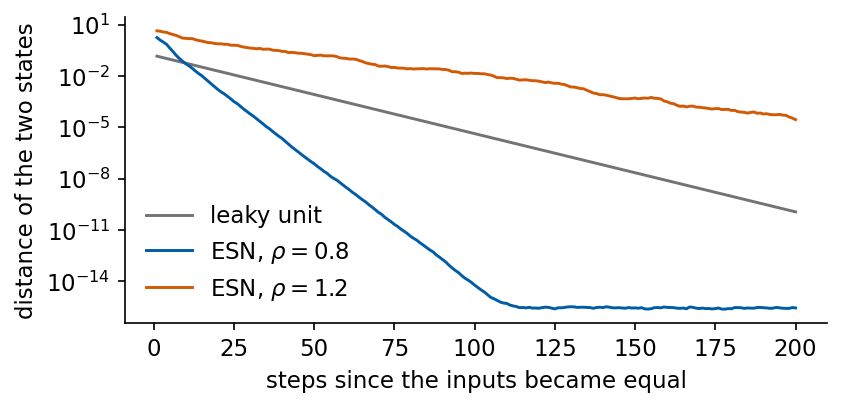

leaky unit      : median distance after 10, 100, 200 steps = 5.53e-02, 4.21e-06, 1.12e-10; fitted rate -0.105 per step
ESN, $\rho=0.8$ : median distance after 10, 100, 200 steps = 5.11e-02, 5.82e-15, 2.70e-16; fitted rate -0.333 per step
ESN, $\rho=1.2$ : median distance after 10, 100, 200 steps = 1.58e+00, 1.39e-02, 2.78e-05; fitted rate -0.056 per step
leaky unit: expected rate ln(1 - alpha) = -0.105 per step


In [8]:
# fading-memory test: inputs differ for the first K0 steps and coincide afterwards; same initial state
K0, K_AFTER, N_ESN, N_PAIRS = 50, 200, 100, 10
rng_fm = np.random.default_rng(11)
def esn_matrix(n, rho, rng):
    # sparse random matrix with 10% Gaussian entries, rescaled to spectral radius rho (as for the ESN of the lecture)
    W0 = rng.normal(size=(n, n)) * (rng.random((n, n)) < 0.1)
    return rho * W0 / np.max(np.abs(np.linalg.eigvals(W0)))
W_in = rng_fm.uniform(-0.5, 0.5, N_ESN)
mats = {rho: esn_matrix(N_ESN, rho, np.random.default_rng(12)) for rho in (0.8, 1.2)}
dist = {"leaky unit": [], "ESN, $\\rho=0.8$": [], "ESN, $\\rho=1.2$": []}
for p in range(N_PAIRS):
    common = rng_fm.uniform(-1, 1, K_AFTER)
    ua = np.concatenate([rng_fm.uniform(-1, 1, K0), common]); ub = np.concatenate([rng_fm.uniform(-1, 1, K0), common])
    xa = xb = 0.0; da = []
    for k in range(K0 + K_AFTER):
        xa = (1 - ALPHA_L) * xa + ALPHA_L * ua[k]; xb = (1 - ALPHA_L) * xb + ALPHA_L * ub[k]
        if k >= K0: da.append(abs(xa - xb))
    dist["leaky unit"].append(da)
    for rho, lab in ((0.8, "ESN, $\\rho=0.8$"), (1.2, "ESN, $\\rho=1.2$")):
        W = mats[rho]; ra = rb = np.zeros(N_ESN); dr = []
        for k in range(K0 + K_AFTER):
            ra = np.tanh(W @ ra + W_in * ua[k]); rb = np.tanh(W @ rb + W_in * ub[k])
            if k >= K0: dr.append(np.linalg.norm(ra - rb))
        dist[lab].append(dr)
med = {lab: np.median(np.array(v), axis=0) for lab, v in dist.items()}
steps_after = np.arange(1, K_AFTER + 1)
rates = {}
for lab, m in med.items():
    ok = (m > 1e-13) & (steps_after <= 150)
    rates[lab] = float(np.polyfit(steps_after[ok], np.log(m[ok]), 1)[0]) if ok.sum() > 10 else float("nan")
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(5.5, 2.6), layout="constrained")
    for (lab, m), col in zip(med.items(), ("0.45", UJBlue, DSOrange)):
        ax.semilogy(steps_after, np.maximum(m, 1e-17), color=col, label=lab)
    ax.set_xlabel("steps since the inputs became equal"); ax.set_ylabel("distance of the two states")
    ax.legend(loc="lower left")
    save(fig, "fig_lab048_fading_memory"); plt.show()
for lab in med:
    print(f"{lab:16s}: median distance after 10, 100, 200 steps = {med[lab][9]:.2e}, {med[lab][99]:.2e}, {med[lab][199]:.2e};"
          f" fitted rate {rates[lab]:+.3f} per step")
print(f"leaky unit: expected rate ln(1 - alpha) = {np.log(1 - ALPHA_L):+.3f} per step")
nums["fading"] = dict(leak_rate=rates["leaky unit"], leak_rate_exact=float(np.log(1 - ALPHA_L)),
                      esn08_rate=rates["ESN, $\\rho=0.8$"], esn08_d100=float(med["ESN, $\\rho=0.8$"][99]),
                      esn12_d200=float(med["ESN, $\\rho=1.2$"][199]), esn12_d10=float(med["ESN, $\\rho=1.2$"][9]))

For the leaky unit the distance decays at the fitted rate $-0.105$ per step, equal to $\ln(1-\alpha)=-0.105$, so the two input histories are forgotten at the rate set by the leak. The ESN at $\rho=0.8$ forgets faster, at the rate $-0.333$ per step, and after 100 steps the median distance is $5.8\times10^{-15}$, the round-off level. At $\rho=1.2$ the distance is still 1.58 after 10 steps and $2.8\times10^{-5}$ after 200, so this reservoir keeps a memory of inputs long gone, which for a forecast is a memory of the wrong past.

<hr/>
## 2. Liquid state machine

### Network

The LSM is a fixed random recurrent network of spiking neurons with a trained linear readout [Maass, Natschläger, Markram (2002)]. We measure voltages in units of the threshold, writing $v_i$ for the voltage of neuron $i$ above rest divided by $v_{\rm th}$, so that every neuron $i=1,\dots,N$ fires at $v_i=1$ and is reset to $v_i=0$, and we measure currents in units of the rheobase, so that $RI/v_{\rm th}$ becomes a dimensionless current $I_i$. The membrane equation of neuron $i$ in the network is
$$\tau_m\frac{dv_i}{dt}=-v_i+I_i(t)+\tau_m\sum_{j}J\,W^{0}_{ij}\sum_{f}\delta\big(t-t_j^{f}\big),$$
where $t_j^f$ are the spike times of neuron $j$, labelled by $f=1,2,\dots$. The sum over $f$ runs over all spikes of neuron $j$, and each delta function is a unit pulse at one spike time, so the term adds the jump $JW^0_{ij}$ to $v_i$ at every spike of neuron $j$. A spike of neuron $j$ raises the voltage of neuron $i$ instantly by $JW^0_{ij}$. The network has $N=300$ neurons. The first 80% are excitatory and the remaining 20% inhibitory, and every ordered pair is connected with probability 0.1, without self-connections. An excitatory spike adds $J$ to the voltage of each of its targets, and an inhibitory spike subtracts $5J$, so the matrix $W^0$ contains the entries $0$, $1$ and $-5$, and $J$ sets the strength of the coupling. Excitatory neurons only excite and inhibitory neurons only inhibit, as in cortex, and inhibition outweighs excitation on average, since $0.8\cdot1<0.2\cdot5$, which follows the classic model of sparse excitatory and inhibitory spiking networks [N. Brunel, J. Comput. Neurosci. **8**, 183 (2000), [doi:10.1023/A:1008925309027](https://doi.org/10.1023/A:1008925309027)]. After a spike a neuron is refractory for $t_{\rm ref}=2$ ms.

The signal enters as a current. The input value $z_k=2s_k-1\in[-1,1]$ of sample $k$ is held for $\Delta=10$ ms, and neuron $i$ receives
$$I_i(t)=\theta_i+G\,w_i\,z_k\qquad\text{for } (k-1)\Delta<t\le k\Delta,$$
with a bias $\theta_i$ uniform in $[0,1]$, below the threshold, and an input weight $w_i$ uniform in $[-1,1]$. The input gain $G$ sets how strongly the signal modulates the currents. A neuron fires only when the signal pushes its current above 1, and since the signs of $w_i$ differ, different neurons respond to different ranges of the signal.

### Synaptic traces and readout

The readout sees each spike train through an exponential filter, the synaptic trace
$$\frac{dx_i}{dt}=-\frac{x_i}{\tau_{s,i}}+\sum_f\delta\big(t-t_i^f\big),$$
with the same sum over spikes, which jumps by 1 at every spike of neuron $i$ and decays with the time constant $\tau_{s,i}$ in between. The feature vector of sample $k$ is $\mathbf r_k=(x_1,\dots,x_N)$ at the end of the sample, $t=k\Delta$, and the forecast is a linear readout $\hat{\mathbf y}_k=W_{\rm out}^\top\mathbf r_k+\mathbf b$ fitted by ridge regression, as for the ESN. A single filter time constant for all neurons gives the readout one memory time only. We therefore draw a different time constant for every neuron, log-uniformly between 5 ms and a largest value $\tau_s$, $\tau_{s,i}=5\,{\rm ms}\,(\tau_s/5\,{\rm ms})^{\xi_i}$ with $\xi_i$ uniform in $[0,1]$. The drawing shows the architecture. The input couplings (dashed blue) and the synapses are random and fixed, with excitatory neurons and their synapses in blue and grey and inhibitory ones in red with bar-ended synapses, the colour of the inhibitory neurons in all figures, and only the readout (orange) is trained.

| | |
|---|---|
| trained | readout $W_{\rm out}$, $\mathbf b$ |
| fixed, random | connections $W^0$, input weights $w_i$, biases $\theta_i$, trace time constants $\tau_{s,i}$ |
| chosen on validation | coupling $J$, input gain $G$, $\tau_m$, $\tau_s$, ridge strength $\beta$ |

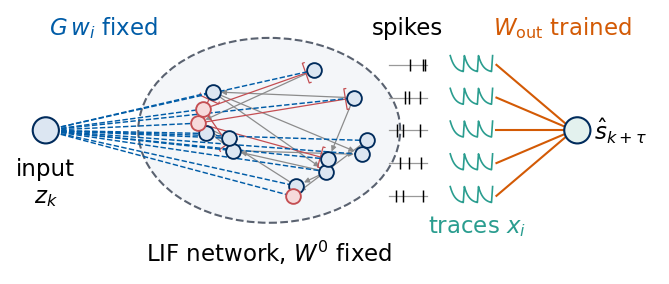

In [9]:
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(5.5, 2.5))
    rng = np.random.default_rng(4)
    n_draw = 14
    ang = rng.uniform(0, 2 * np.pi, n_draw); rad = np.sqrt(rng.uniform(0.05, 1, n_draw))
    P = np.c_[2.9 + 1.3 * rad * np.cos(ang), 1.2 + 0.9 * rad * np.sin(ang)]
    inhib = np.arange(n_draw) >= 11                                   # drawn inhibitory neurons
    ax.add_patch(Ellipse((2.9, 1.2), 3.4, 2.4, fc="#F4F6F9", ec=UJGray, ls="--", lw=1.0, zorder=0))
    for i in range(n_draw):                                           # fixed random synapses
        for j in range(n_draw):
            if i != j and rng.random() < 0.13:
                ax.annotate("", xy=P[j], xytext=P[i], arrowprops=dict(arrowstyle="-|>" if not inhib[i] else "-[",
                            color="0.55" if not inhib[i] else INH, lw=0.6, shrinkA=4, shrinkB=4,
                            mutation_scale=5), zorder=1)
    s_xy = np.array([0.0, 1.2])
    for i in range(n_draw):                                           # fixed input currents
        ax.plot(*np.c_[s_xy, P[i]], color=UJBlue, lw=0.7, ls="--", zorder=1)
    ax.scatter(*P[~inhib].T, s=50, color="#DCE6F2", edgecolor=UJNavy, lw=0.9, zorder=3)
    ax.scatter(*P[inhib].T, s=50, color="#F6DADB", edgecolor=INH, lw=0.9, zorder=3)
    ax.add_patch(Circle(s_xy, 0.17, fc="#DCE6F2", ec=UJNavy, zorder=3))
    ax.text(s_xy[0], 0.85, "input\n" + r"$z_k$", ha="center", va="top")
    # spike trains -> traces -> readout
    xt = 5.25
    for m, yy in enumerate(np.linspace(0.35, 2.05, 5)):
        ax.plot([4.45, 4.95], [yy, yy], color="0.6", lw=0.6)
        ax.vlines(4.5 + 0.45 * rng.random(3), yy - 0.08, yy + 0.08, color="k", lw=0.7)
        tt = np.linspace(0, 1, 40)
        ax.plot(xt + 0.55 * tt, yy - 0.1 + 0.22 * np.exp(-3 * ((tt * 3) % 1)), color=Teal, lw=0.8)
        ax.plot([xt + 0.6, 6.85], [yy, 1.2], color=DSOrange, lw=1.0)
    ax.add_patch(Circle((6.9, 1.2), 0.17, fc="#E3F1EE", ec=UJNavy, zorder=3))
    ax.text(7.12, 1.2, r"$\hat s_{k+\tau}$", ha="left", va="center")
    ax.text(0.75, 2.45, r"$G\,w_i$ fixed", color=UJBlue, ha="center")
    ax.text(2.9, -0.2, r"LIF network, $W^0$ fixed", ha="center", va="top")
    ax.text(4.7, 2.45, "spikes", ha="center"); ax.text(5.6, 0.12, r"traces $x_i$", ha="center", va="top", color=Teal)
    ax.text(6.7, 2.45, r"$W_{\rm out}$ trained", color=DSOrange, ha="center")
    ax.set_xlim(-0.4, 7.9); ax.set_ylim(-0.6, 2.7); ax.set_aspect("equal"); ax.axis("off")
    save(fig, "fig_lab048_lsm_diagram"); plt.show()

### LIF network implementation in JAX

The simulation uses the Euler step $\Delta t=0.5$ ms, 20 steps per input sample, with $\alpha=\Delta t/\tau_m\le0.1$ for all membrane time constants used below. In each step every voltage relaxes towards its current, receives the jumps from the spikes of the previous step, is clamped at zero while refractory, and is compared with the threshold. The traces decay by $e^{-\Delta t/\tau_{s,i}}$ and add the new spikes. One call simulates a batch of copies of the same network, each with its own coupling, gain, time constants, input and initial voltages, so that the recurrent input of all copies is one matrix product per step. The whole time loop is one `jax.lax.scan`. The batch holds at most 27 copies, a size that fits in memory and splits the grid of 54 network settings below into two calls. The results do not depend on this number.

As a check, the network without coupling, $J=0$, driven by a constant input must fire at the rate of the formula above, now in dimensionless form, $\nu_i=1/\big(t_{\rm ref}+\tau_m\ln[I_i/(I_i-1)]\big)$ for $I_i>1$. We hold $z_k=0.5$ for one second at $G=2$ and $\tau_m=10$ ms and compare the spike counts of the last 0.8 s with the formula.

In [10]:
DT, N_SUB, T_REF, TAU_LO = 0.5, 20, 2.0, 5.0    # Euler step (ms), steps per 10 ms input sample, refractory time, shortest trace time
N_REF = int(round(T_REF / DT))
SAMPLE_MS = DT * N_SUB

def lsm_base(N, seed, p=0.1, frac_e=0.8, g=5.0, b_range=(0.0, 1.0)):
    # fixed random parts: W0[i, j] = effect of a spike of j on i in units of J, input weights, biases theta_i, trace positions xi
    rng = np.random.default_rng(seed)
    n_e = int(round(frac_e * N))
    A = (rng.random((N, N)) < p) & ~np.eye(N, dtype=bool)
    W0 = A * np.where(np.arange(N) < n_e, 1.0, -g)[None, :]
    return dict(W0=W0, w=rng.uniform(-1, 1, N), theta=rng.uniform(*b_range, N), xi=rng.uniform(0, 1, N), n_e=n_e)

def trace_times(xi, tau_s):
    # tau_{s,i} = 5 ms (tau_s / 5 ms)^{xi_i}, one row per batch element
    return TAU_LO * (np.asarray(tau_s, float)[:, None] / TAU_LO) ** np.asarray(xi)[None, :]

@partial(jax.jit, static_argnames=("record",))
def lsm_run(W0, w, theta, U, J, G, tau_m, TS, v0, record=False):
    # U: (T, B) inputs z_k; J, G, tau_m: (B,); TS: (B, N) trace time constants; v0: (B, N) initial voltages
    # returns the traces at the end of every sample, (T, B, N), and the spikes of every Euler step if record
    f = jnp.float32
    W0T = W0.T.astype(f); w = w.astype(f); theta = theta.astype(f)
    a = (DT / tau_m).astype(f)[:, None]                  # alpha = dt / tau_m
    d_s = jnp.exp(-DT / TS).astype(f)                    # trace decay per Euler step
    J = J.astype(f)[:, None]; G = G.astype(f)[:, None]
    def euler(st, I):
        v, ref, x, spk = st
        v = v + a * (-v + I) + J * (spk @ W0T)           # leak, input current, jumps from the spikes of the last step
        v = jnp.where(ref > 0, 0.0, v)                   # refractory neurons stay at the reset value
        ref = jnp.maximum(ref - 1, 0)
        new = (v >= 1.0).astype(f)                       # threshold
        v = jnp.where(new > 0, 0.0, v)                   # reset
        ref = jnp.where(new > 0, N_REF, ref)
        st = (v, ref, x * d_s + new, new)
        return st, (new > 0 if record else None)
    def sample_plain(st, uk):
        I = theta[None, :] + G * w[None, :] * uk.astype(f)[:, None]
        st, S = jax.lax.scan(lambda s_, _: euler(s_, I), st, None, length=N_SUB)
        return st, (st[2], S)
    z = jnp.zeros(v0.shape, f)
    st0 = (v0.astype(f), jnp.zeros(v0.shape, jnp.int32), z, z)
    _, (X, S) = jax.lax.scan(sample_plain, st0, U)
    return (X, S) if record else X

BATCH = 27        # copies simulated in one call: fits in memory and splits the 54-setting grid into two calls

def lsm_features(net, u, settings, v0=None, TS=None, chunk=BATCH):
    # traces (T, B, N) in float64 for a list of settings (J, G, tau_m, tau_s), all driven by the input u
    out = []
    for c in range(0, len(settings), chunk):
        st = np.array(settings[c:c + chunk], float)
        B, N = len(st), len(net["theta"])
        ts_ = trace_times(net["xi"], st[:, 3]) if TS is None else TS[c:c + chunk]
        v_ = np.zeros((B, N)) if v0 is None else v0[c:c + chunk]
        X = lsm_run(net["W0"], net["w"], net["theta"], jnp.asarray(np.repeat(np.asarray(u)[:, None], B, 1)),
                    jnp.asarray(st[:, 0]), jnp.asarray(st[:, 1]), jnp.asarray(st[:, 2]), jnp.asarray(ts_), jnp.asarray(v_))
        out.append(np.asarray(X, np.float64))
    return np.concatenate(out, 1)

N_LSM = 300
net = lsm_base(N_LSM, seed=0)
print(f"N = {N_LSM}: {net['n_e']} excitatory, {N_LSM - net['n_e']} inhibitory neurons,"
      f" {int((net['W0'] != 0).sum(1).mean())} incoming synapses per neuron on average")

# check: J = 0, constant input z = 0.5 for 1 s (100 samples), G = 2, tau_m = 10 ms
u_c = np.full(100, 0.5)
_, S_c = lsm_run(net["W0"], net["w"], net["theta"], jnp.asarray(u_c[:, None]), jnp.zeros(1), jnp.full(1, 2.0),
                 jnp.full(1, 10.0), jnp.asarray(trace_times(net["xi"], [100.0])), jnp.zeros((1, N_LSM)), record=True)
S_c = np.asarray(S_c)[:, :, 0, :].reshape(-1, N_LSM)            # (Euler steps, N)
count = S_c[int(200 / DT):].sum(0)                                # spikes in the last 0.8 s
I_c = net["theta"] + 2.0 * net["w"] * 0.5
f_c = np.zeros(N_LSM)
f_c[I_c > 1] = 1000.0 / (T_REF + 10.0 * np.log(I_c[I_c > 1] / (I_c[I_c > 1] - 1)))
dev = np.abs(count / 0.8 - f_c)
nums["net_check"] = dict(max_dev_Hz=float(dev.max()), max_rate_Hz=float(f_c.max()), n_firing=int((f_c > 0).sum()))
print(f"J = 0, constant input: {int((f_c > 0).sum())} of {N_LSM} neurons above threshold, rates up to {f_c.max():.0f} Hz,"
      f" max |simulated - formula| = {dev.max():.1f} Hz")

N = 300: 240 excitatory, 60 inhibitory neurons, 30 incoming synapses per neuron on average


J = 0, constant input: 83 of 300 neurons above threshold, rates up to 105 Hz, max |simulated - formula| = 2.5 Hz


At constant input, 83 of the 300 uncoupled neurons have a current above threshold, with rates up to 105 Hz, and the simulated rates differ from the formula by at most 2.5 Hz. This deviation comes from the Euler step of 0.5 ms and from counting whole spikes in a window of 0.8 s.

### Spikes driven by the Santa Fe signal

The five benchmark signals and the forecasting protocol are the ones used for the ESN. The first coordinate $x$ of the Lorenz-63 system, $\dot x=10\,(y-x)$, $\dot y=x\,(28-z)-y$, $\dot z=xy-\tfrac83 z$, is integrated by the fourth-order Runge–Kutta method (RK4) and sampled every $\Delta t=0.02$, the Mackey–Glass delay equation
$$\dot s(t)=\frac{0.2\, s(t-\tau_{\rm MG})}{1+s(t-\tau_{\rm MG})^{10}}-0.1\, s(t)$$
is sampled once per time unit for the delays $\tau_{\rm MG}=15$, 25 and 35, and the Santa Fe series (data set A) is the measured intensity of a far-infrared NH$_3$ laser. Every signal has 4000 samples and is rescaled to $[0,1]$ with the minimum and maximum of its first 3000 samples.

In [11]:
# Lorenz-63: x' = 10 (y - x), y' = x (28 - z) - y, z' = x y - 8/3 z; RK4 with h=0.01, sampled every 2 steps (dt=0.02);
# initial state (1,1,1), first 50 time units discarded; we keep the x component.
def lorenz_rhs(u):
    x, y, z = u
    return jnp.array([10.0 * (y - x), x * (28.0 - z) - y, x * y - 8.0 / 3.0 * z])

def rk4_step(f, u, h):
    k1 = f(u); k2 = f(u + 0.5*h*k1); k3 = f(u + 0.5*h*k2); k4 = f(u + h*k3)
    return u + h/6.0*(k1 + 2*k2 + 2*k3 + k4)

@partial(jax.jit, static_argnums=(0, 1, 2))
def lorenz_trajectory(n_samples, sub=2, n_discard=2500, h=0.01):
    def one_sample(u, _):
        u = jax.lax.fori_loop(0, sub, lambda i, v: rk4_step(lorenz_rhs, v, h), u)
        return u, u
    u0 = jnp.array([1.0, 1.0, 1.0])
    u, _ = jax.lax.scan(one_sample, u0, None, length=n_discard)
    _, traj = jax.lax.scan(one_sample, u, None, length=n_samples)
    return traj

# Mackey-Glass: ds/dt = 0.2 s(t-tau)/(1+s(t-tau)^10) - 0.1 s(t); RK4 with h=0.1, delayed value at half steps by linear interpolation,
# constant history 1.2 on [-tau, 0], first 3000 fine steps discarded, every 10th point kept (unit sampling).
def mackey_glass(tau, n_samples, h=0.1, x0=1.2, transient=3000, every=10):
    lag = int(round(tau / h))
    f = lambda x, xd: 0.2 * xd / (1.0 + xd**10) - 0.1 * x
    def step(buf, _):
        x, xd0, xd1 = buf[-1], buf[0], buf[1]
        xdh = 0.5 * (xd0 + xd1)
        k1 = f(x, xd0); k2 = f(x + 0.5*h*k1, xdh); k3 = f(x + 0.5*h*k2, xdh); k4 = f(x + h*k3, xd1)
        xn = x + h/6.0*(k1 + 2*k2 + 2*k3 + k4)
        return jnp.concatenate([buf[1:], xn[None]]), xn
    _, xs = jax.lax.scan(step, jnp.full(lag + 1, x0), None, length=transient + n_samples * every)
    x = np.concatenate([np.full(lag + 1, x0), np.asarray(xs)])
    return x[transient::every][:n_samples]

def santafe():
    # Santa Fe laser data, set A: measured intensity of a far-infrared NH3 laser
    for path in ("santafe_laser.txt", "data/santafe_laser.txt", "../../Lecture_8/Notebooks/data/santafe_laser.txt"):
        if os.path.exists(path):
            return np.loadtxt(path).astype(float)
    raise FileNotFoundError("santafe_laser.txt")

N_SAMPLES, N_TRAIN, N_VAL, TAU_MAX = 4000, 3000, 500, 50
def rescale01(s, n_train=N_TRAIN):
    lo, hi = s[:n_train].min(), s[:n_train].max()
    return (s - lo) / (hi - lo)

raw = {"Lorenz": np.asarray(lorenz_trajectory(N_SAMPLES)[:, 0]),
       "MG15": mackey_glass(15, N_SAMPLES), "MG25": mackey_glass(25, N_SAMPLES),
       "MG35": mackey_glass(35, N_SAMPLES), "SantaFe": santafe()[:N_SAMPLES]}
SIGNALS = list(raw)
LABEL = {"Lorenz": "Lorenz-63", "MG15": r"MG $\tau_{\rm MG}=15$", "MG25": r"MG $\tau_{\rm MG}=25$",
         "MG35": r"MG $\tau_{\rm MG}=35$", "SantaFe": "Santa Fe laser"}
sig = {name: rescale01(x) for name, x in raw.items()}     # [0, 1] on the training block (first 3000 samples)
print({n: sig[n].shape for n in SIGNALS})

{'Lorenz': (4000,), 'MG15': (4000,), 'MG25': (4000,), 'MG35': (4000,), 'SantaFe': (4000,)}


We drive the network with the first 60 samples of the Santa Fe signal, 600 ms of neuron time, at the coupling $J=0.01$, gain $G=2$, $\tau_m=10$ ms and $\tau_s=300$ ms. The raster plot marks every spike of every neuron as a dot at its time, with the excitatory neurons (blue) sorted by their input weight $w_i$ from negative (bottom) to positive (top), followed by the inhibitory neurons (red, the colour of the inhibitory neurons in the drawing of the network). The top panel shows the input $z_k=2s_k-1$ on the same time axis. The rescaled laser intensity is small most of the time, so $z_k$ is mostly negative, and the neurons with $w_i<0$ fire in bursts between the laser pulses, while each pulse silences them. The population encodes the signal in the times of these bursts. Neurons with $w_i>0$ would need $z_k>0$ and fire rarely. Over the whole signal the mean rate is 19.0 Hz, and 104 neurons never fire.

mean rate 19.0 Hz, silent neurons 104


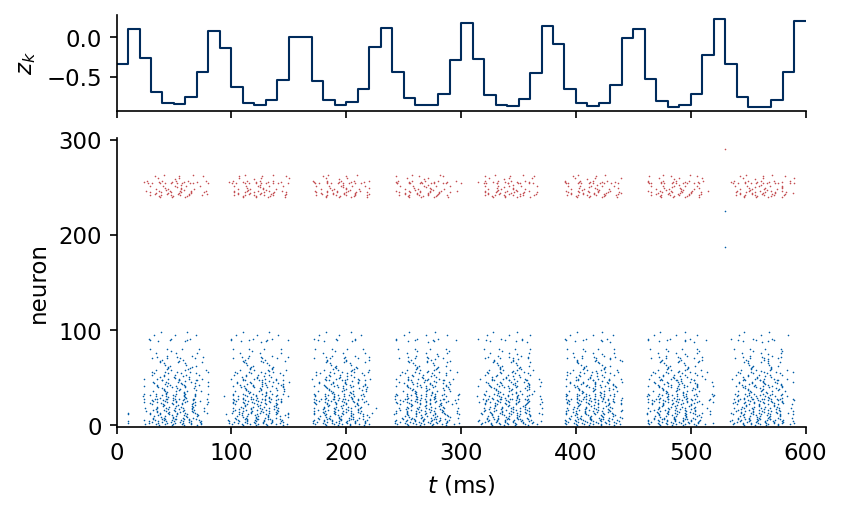

In [12]:
SHOW = (0.01, 2.0, 10.0, 300.0)                 # (J, G, tau_m, tau_s) of the illustrations
u_sf = 2 * sig["SantaFe"] - 1
X_show, S_show = lsm_run(net["W0"], net["w"], net["theta"], jnp.asarray(u_sf[:, None]), jnp.full(1, SHOW[0]),
                         jnp.full(1, SHOW[1]), jnp.full(1, SHOW[2]), jnp.asarray(trace_times(net["xi"], [SHOW[3]])),
                         jnp.zeros((1, N_LSM)), record=True)
X_show = np.asarray(X_show, np.float64)[:, 0]                     # (T, N) traces at the sample ends
S_show = np.asarray(S_show)[:, :, 0, :]                           # (T, N_SUB, N) spikes
tot = S_show.sum((0, 1))
nums["raster"] = dict(mean_rate_Hz=float(tot.mean() / (len(u_sf) * SAMPLE_MS / 1000)), n_silent=int((tot == 0).sum()))
print(f"mean rate {nums['raster']['mean_rate_Hz']:.1f} Hz, silent neurons {(tot == 0).sum()}")

K_RAS = 60
order = np.r_[np.argsort(net["w"][:net["n_e"]]), net["n_e"] + np.argsort(net["w"][net["n_e"]:])]
S_r = S_show[:K_RAS].reshape(-1, N_LSM)[:, order]
t_r = DT * np.arange(1, S_r.shape[0] + 1)
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(2, 1, figsize=(5.5, 3.3), sharex=True, layout="constrained",
                            gridspec_kw={"height_ratios": [1, 3]})
    axs[0].step(SAMPLE_MS * np.arange(K_RAS + 1), np.r_[u_sf[0], u_sf[:K_RAS]], where="pre", color=UJNavy, lw=1.0)
    axs[0].set_ylabel("$z_k$")
    ti, ni = np.nonzero(S_r)
    exc = ni < net["n_e"]
    axs[1].scatter(t_r[ti[exc]], ni[exc], s=0.6, color=UJBlue, lw=0)
    axs[1].scatter(t_r[ti[~exc]], ni[~exc], s=0.6, color=INH, lw=0)
    axs[1].set_ylabel("neuron"); axs[1].set_xlabel("$t$ (ms)"); axs[1].set_ylim(-2, N_LSM + 2); axs[1].set_xlim(0, K_RAS * SAMPLE_MS)
    save(fig, "fig_lab048_raster"); plt.show()

The readout sees the traces. The next figure shows the rescaled signal $s_k$ over the first 300 samples (top) and the traces $x_i$ of three neurons at the sample ends, one with a short time constant $\tau_{s,i}$ that follows the individual pulses and two with longer ones that integrate the firing over many pulses. The traces are counts of recent spikes, weighted by their age, and each of them is a nonlinear functional of the input history with its own memory time.

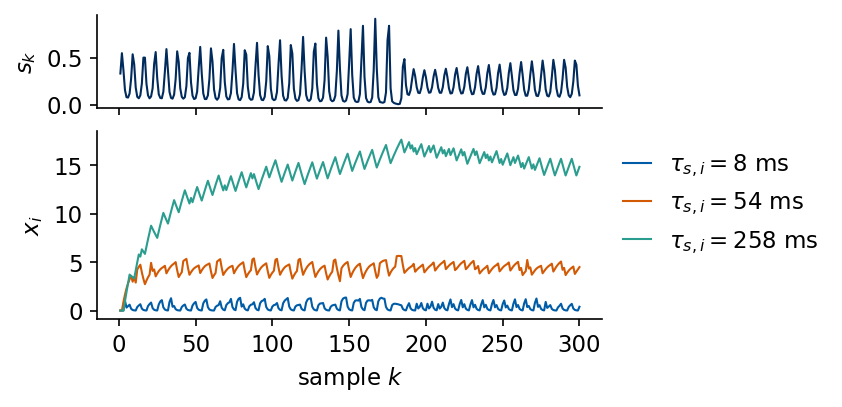

In [13]:
TS_show = trace_times(net["xi"], [SHOW[3]])[0]
busy = tot >= np.quantile(tot, 0.8)                                  # among the 20% most active neurons
pick = [int(np.argmin(np.abs(np.log(TS_show / t_)) + 1e3 * ~busy)) for t_ in (8.0, 60.0, 250.0)]
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(2, 1, figsize=(5.5, 2.6), sharex=True, layout="constrained", gridspec_kw={"height_ratios": [1, 2]})
    kk = np.arange(1, 301)
    axs[0].plot(kk, sig["SantaFe"][:300], color=UJNavy, lw=1.0); axs[0].set_ylabel("$s_k$")
    for i, c in zip(pick, (UJBlue, DSOrange, Teal)):
        axs[1].plot(kk, X_show[:300, i], color=c, lw=1.0, label=rf"$\tau_{{s,i}}={TS_show[i]:.0f}$ ms")
    axs[1].set_ylabel("$x_i$"); axs[1].set_xlabel("sample $k$")
    axs[1].legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), handlelength=1.2)
    save(fig, "fig_lab048_traces"); plt.show()

### Echo state property for spikes

The echo state property requires that the state of the reservoir becomes a function of the input history alone, so that two copies started from different states and driven by the same input approach each other [H. Jaeger, GMD Report 148 (2001), [pdf](https://www.ai.rug.nl/minds/uploads/EchoStatesTechRep.pdf)]. We start two copies of the network with voltages drawn uniformly from $[0,1]$ and drive both with the first 1000 Santa Fe samples. Two quantities measure their difference. The relative trace distance
$$D_k=\frac{\|\mathbf r_k-\mathbf r'_k\|}{\langle\|\mathbf r_k\|\rangle_k}$$
compares the feature vectors, normalised by the mean length of the feature vector over the run. The differing fraction counts the neurons that still fire out of step. For every neuron we take the part of its trace that was added during sample $k$, $x_{i,k}-e^{-\Delta/\tau_{s,i}}x_{i,k-1}$ with the sample length $\Delta=10$ ms and $x_{i,0}=0$ before the first sample. This increment is the sum of the spikes of neuron $i$ in sample $k$, each weighted by its decay until the end of the sample. A neuron counts as differing when its increments in the two copies differ by more than $10^{-3}$. One spike adds at least $e^{-10/5}\approx0.14$, far above this threshold and far above the round-off of single precision, so the test detects every sample in which a neuron emits a different number of spikes or spikes at different Euler steps. The left panel shows $D_k$ and the right panel the differing fraction, averaged over windows of 20 samples, for four couplings $J$ at $G=2$, $\tau_m=10$ ms and $\tau_s=300$ ms. The dashed line is a network with the biases $\theta_i$ uniform in $[1,2]$, above threshold, and $J=0$.

Without coupling, the subthreshold network locks to the input. After 59 samples both copies emit identical spike trains, and $D_k$ then decays exponentially, since the remaining trace difference is the memory of the first spikes, which fades with the trace time constants. For $J=0.01$ the copies lock after 532 samples. For $J=0.03$ and $J=0.1$ a fraction of 0.15 and 0.26 of the neurons still fire differently in the last 100 samples. A spike in one copy and none in the other changes the voltages of about 30 neighbours, and with strong coupling these differences multiply, the spiking analogue of a spectral radius above one. The tonically firing network fails as well, although it has no coupling at all. A neuron with a current above threshold fires periodically, and two copies that start at different phases of this cycle keep their phase difference under constant input. A current that moves the neuron across its threshold makes the spike times reproducible, which Mainen and Sejnowski observed in cortical neurons, whose spike times varied from trial to trial under a constant current and repeated under a fluctuating one [Z. F. Mainen, T. J. Sejnowski, Science **268**, 1503 (1995), [doi:10.1126/science.7770778](https://doi.org/10.1126/science.7770778)]. This is why the biases of our network lie below threshold.

J0     : D at k = 1000: 0.0e+00, differing fraction in the last 100 samples 0.000, identical spike trains from sample 59
J0.01  : D at k = 1000: 1.4e-13, differing fraction in the last 100 samples 0.000, identical spike trains from sample 532
J0.03  : D at k = 1000: 5.1e-02, differing fraction in the last 100 samples 0.151, identical spike trains from sample None
J0.1   : D at k = 1000: 1.1e-01, differing fraction in the last 100 samples 0.262, identical spike trains from sample None
tonic  : D at k = 1000: 1.6e-02, differing fraction in the last 100 samples 0.057, identical spike trains from sample None


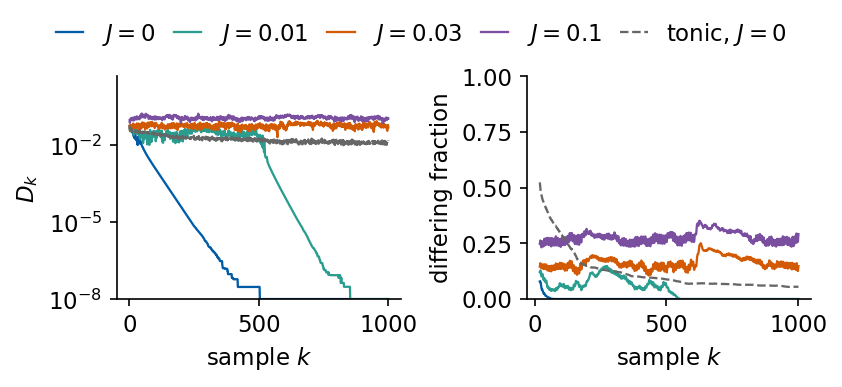

In [14]:
T_ESP = 1000
u_esp = u_sf[:T_ESP]
net_tonic = lsm_base(N_LSM, seed=0, b_range=(1.0, 2.0))

def esp_pair(net_, settings, seed=1, u=u_esp):
    # two copies with initial voltages uniform in [0, 1] for each setting; returns D_k and the differing fraction
    rng = np.random.default_rng(seed)
    B = len(settings)
    va, vb = rng.uniform(0, 1, (B, N_LSM)), rng.uniform(0, 1, (B, N_LSM))
    X = lsm_features(net_, u, list(settings) * 2, v0=np.r_[va, vb])
    Xa, Xb = X[:, :B], X[:, B:]
    D = np.linalg.norm(Xa - Xb, axis=2) / np.linalg.norm(Xa, axis=2).mean(0)
    # trace increment of sample k: x_k - exp(-Delta/tau_s) x_{k-1} = spikes of sample k, each decayed to the sample end;
    # traces are zero before the first sample. A neuron differs when its increments in the two copies differ by > 1e-3.
    d_s = np.exp(-SAMPLE_MS / trace_times(net_["xi"], np.array([s_[3] for s_ in settings])))[None]
    prev_a = np.concatenate([np.zeros_like(Xa[:1]), Xa[:-1]]); prev_b = np.concatenate([np.zeros_like(Xb[:1]), Xb[:-1]])
    Ea = Xa - d_s * prev_a; Eb = Xb - d_s * prev_b
    frac = (np.abs(Ea - Eb) > 1e-3).mean(2)
    return D, frac

J_ESP = (0.0, 0.01, 0.03, 0.1)
D_esp, F_esp = esp_pair(net, [(J_, 2.0, 10.0, 300.0) for J_ in J_ESP])
D_ton, F_ton = esp_pair(net_tonic, [(0.0, 2.0, 10.0, 300.0)])
nums["esp"] = {}
for i, J_ in enumerate(J_ESP + ("tonic",)):
    D_, F_ = (D_esp[:, i], F_esp[:, i]) if J_ != "tonic" else (D_ton[:, 0], F_ton[:, 0])
    lock = np.nonzero(F_ > 0)[0]
    k_lock = int(lock[-1] + 2) if len(lock) and lock[-1] < T_ESP - 1 else None   # first sample after the last difference
    key = f"J{J_:g}" if J_ != "tonic" else "tonic"
    nums["esp"][key] = dict(D_end=float(D_[-1]), frac_end=float(F_[-100:].mean()), k_lock=k_lock)
    print(f"{key:7s}: D at k = {T_ESP}: {D_[-1]:.1e}, differing fraction in the last 100 samples {F_[-100:].mean():.3f},"
          f" identical spike trains from sample {k_lock}")

def smooth(a, w=20):
    return np.convolve(a, np.ones(w) / w, mode="valid")
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.5), layout="constrained")
    cols = (UJBlue, Teal, DSOrange, "#7B4FA0")
    kk = np.arange(1, T_ESP + 1)
    for i, (J_, c) in enumerate(zip(J_ESP, cols)):
        axs[0].semilogy(kk, np.maximum(D_esp[:, i], 1e-8), color=c, lw=1.1, label=rf"$J={J_:g}$")
        axs[1].plot(kk[19:], smooth(F_esp[:, i]), color=c, lw=1.1)
    axs[0].semilogy(kk, np.maximum(D_ton[:, 0], 1e-8), color="0.4", ls="--", lw=1.1, label="tonic, $J=0$")
    axs[1].plot(kk[19:], smooth(F_ton[:, 0]), color="0.4", ls="--", lw=1.1)
    axs[0].set_xlabel("sample $k$"); axs[0].set_ylabel("$D_k$"); axs[0].set_ylim(1e-8, 5)
    axs[1].set_xlabel("sample $k$"); axs[1].set_ylabel("differing fraction"); axs[1].set_ylim(0, 1)
    fig.legend(*axs[0].get_legend_handles_labels(), loc="outside upper center", ncol=5, handlelength=1.2, columnspacing=0.8)
    save(fig, "fig_lab048_esp"); plt.show()

The scan below repeats the test over a grid of couplings for three input gains, with three pairs of initial states each, and plots the median over the pairs of the differing fraction in the last 100 of the 1000 samples. A stronger input makes more neurons fire, so more spikes travel through the couplings, and the locking fails at smaller couplings. The largest coupling on the grid with a median differing fraction below 0.01 is 0.02 for $G=1$, 0.01 for $G=2$ and 0.01 for $G=4$. These values hold for this network and this input.

G = 1.0: median differing fraction 0.000, 0.000, 0.000, 0.000, 0.000, 0.063, 0.094, 0.191
G = 2.0: median differing fraction 0.000, 0.000, 0.000, 0.077, 0.106, 0.143, 0.178, 0.259
G = 4.0: median differing fraction 0.000, 0.000, 0.000, 0.127, 0.157, 0.201, 0.247, 0.312


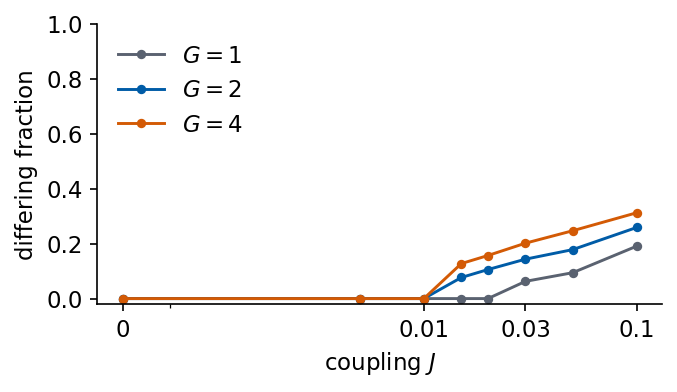

In [15]:
J_SCAN = (0.0, 0.005, 0.01, 0.015, 0.02, 0.03, 0.05, 0.1)
G_SCAN = (1.0, 2.0, 4.0)
grid_esp = [(J_, G_, 10.0, 300.0) for G_ in G_SCAN for J_ in J_SCAN]
F_scan = np.median(np.array([esp_pair(net, grid_esp, seed=sd)[1][-100:].mean(0) for sd in (1, 2, 3)]), 0)
F_scan = F_scan.reshape(len(G_SCAN), len(J_SCAN))
nums["esp_scan"] = dict(J=list(J_SCAN), G=list(G_SCAN), frac=F_scan.tolist(), J_crit={})
for gi, G_ in enumerate(G_SCAN):
    ok = np.nonzero(F_scan[gi] < 0.01)[0]
    nums["esp_scan"]["J_crit"][str(G_)] = float(J_SCAN[ok.max()]) if len(ok) else None
    print(f"G = {G_}: median differing fraction " + ", ".join(f"{v:.3f}" for v in F_scan[gi]))
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(4.4, 2.5), layout="constrained")
    for gi, (G_, c) in enumerate(zip(G_SCAN, (UJGray, UJBlue, DSOrange))):
        ax.plot(J_SCAN, F_scan[gi], "o-", ms=3.5, color=c, label=rf"$G={G_:g}$")
    ax.set_xscale("symlog", linthresh=0.005); ax.set_xticks([0, 0.01, 0.03, 0.1], ["0", "0.01", "0.03", "0.1"])
    ax.set_xlabel("coupling $J$"); ax.set_ylabel("differing fraction"); ax.set_ylim(-0.02, 1)
    ax.legend(loc="upper left")
    save(fig, "fig_lab048_esp_scan"); plt.show()

The test is finite. It uses 1000 samples of one input and three pairs of initial states, and at $J=0.01$ and $G=2$ the two copies of the single run above locked only after 532 samples. Within these limits a spiking reservoir behaves as one with the echo state property for this input when its neurons sit below threshold and its coupling is weak, at most about $J=0.01$ at the gain $G=2$.

### Memory capacity

The memory capacity measures how much of an unpredictable input a linear readout can recover. The input $u_k$ is drawn independently and uniformly from $[-1,1]$ and fed to the network as $z_k=u_k$, and for every delay $d=1,\dots,100$ a ridge readout of $\mathbf r_k$ is fitted to $u_{k-d}$. Its capacity on test data is $C(d)=r^2(\hat u_{k-d},u_{k-d})$, the squared Pearson coefficient, and the memory capacity is $\mathrm{MC}=\sum_{d}C(d)$, bounded by the number of features [J. Dambre, D. Verstraeten, B. Schrauwen, S. Massar, Sci. Rep. **2**, 514 (2012), [doi:10.1038/srep00514](https://doi.org/10.1038/srep00514)]. After 200 discarded samples we fit on 4000 samples, choose one ridge strength for all delays by the largest sum of $C(d)$ on the next 1000 and test on the last 2000. This protocol is the one of the memory-capacity measurement of the ESN. For comparison we compute the same curve for ESNs with $N=50$ and $N=300$ tanh units, spectral radius $\rho=0.95$, input scaling $\sigma_{\rm in}=0.1$ and leak rate $\alpha=1$, drawn as in the ESN forecasts below.

The figure shows $C(d)$ for three settings of the LSM with 300 neurons, (a) $J=0.01$, $G=2$, $\tau_m=10$ ms, $\tau_s=100$ ms, (b) the same with $\tau_s=1000$ ms and (c) $J=0$, $G=4$, $\tau_m=5$ ms, $\tau_s=300$ ms, for an LSM with 50 neurons at setting (c) and for the two ESNs. The ESNs store 19.9 and 44.1 past inputs, 40% of the bound for $N=50$ and 15% of it for $N=300$. The LSM stores between 2.1 and 3.0 with 300 neurons and 2.5 with 50, and longer trace times hardly change this. The present input is encoded well, with $C(0)=0.978$ at setting (c), and already $C(1)$ is 0.66. We offer two hypotheses for the short memory, which we have not tested separately. Each trace is a sum of decaying exponentials over past spikes, and separating the contribution of one particular past sample from such sums may be an ill-conditioned inversion, because exponentials with nearby time constants are almost linearly dependent. In addition, a random input value held for 10 ms produces at most a few spikes per neuron, a coarse and strongly nonlinear code of $u_k$. The ESN instead mixes its state through the recurrent matrix, which moves information about each past input into new directions of the state space. A white-noise input is the hardest case for this code, since every sample is new. A smooth signal changes little from sample to sample, and its recent history is summarised well by the traces.

ESN50: MC / N = 0.40
ESN300: MC / N = 0.15


LSM 300, setting c: C(0) = 0.978, C(1) = 0.659
ESN50        MC =  19.9, C(d) > 0.5 up to d = 19
ESN300       MC =  44.1, C(d) > 0.5 up to d = 44
LSM300_a     MC =   2.1, C(d) > 0.5 up to d = 1
LSM300_b     MC =   2.5, C(d) > 0.5 up to d = 0
LSM300_c     MC =   3.0, C(d) > 0.5 up to d = 1
LSM50_c      MC =   2.5, C(d) > 0.5 up to d = 0


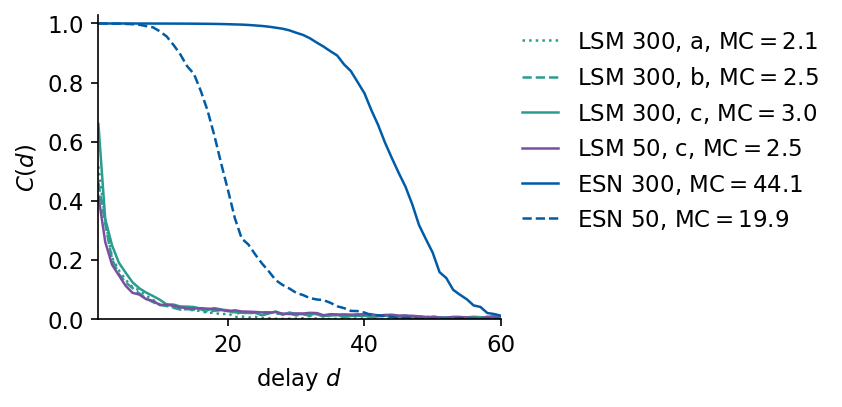

In [16]:
def esn_base(N, seed, density=0.1):
    # random sparse W rescaled to spectral radius 1 and input vector uniform in [-1, 1]; scaled later by rho, sigma_in
    rng = np.random.default_rng(seed)
    W = rng.normal(size=(N, N)) * (rng.random((N, N)) < density)
    W /= np.max(np.abs(np.linalg.eigvals(W)))
    return W, rng.uniform(-1.0, 1.0, size=N)

@jax.jit
def esn_states(W, w_in, u, alpha, x0):
    # r_k = (1 - alpha) r_{k-1} + alpha tanh(W r_{k-1} + w_in u_k), returns all states (T, N)
    def step(x, uk):
        x = (1.0 - alpha) * x + alpha * jnp.tanh(W @ x + w_in * uk)
        return x, x
    _, X = jax.lax.scan(step, x0, u)
    return X

def ridge_path(F_fit, Y_fit, betas):
    # centred ridge regressions for several ridge strengths from one eigendecomposition; yields (beta, W, b)
    fm, ym = F_fit.mean(0), Y_fit.mean(0)
    Fc = F_fit - fm
    lam, V = np.linalg.eigh(Fc.T @ Fc)
    P = V.T @ (Fc.T @ (Y_fit - ym))
    for beta in betas:
        W = V @ (P / (lam + beta)[:, None])
        yield beta, W, ym - fm @ W

def r2_columns(pred, true):
    pc, tc = pred - pred.mean(0), true - true.mean(0)
    return (pc * tc).sum(0) ** 2 / ((pc ** 2).sum(0) * (tc ** 2).sum(0))

MC_BETAS = (1e-8, 1e-6, 1e-4, 1e-2, 1.0, 1e2)
n_wash, n_fit, n_val, n_test, D_MAX = 200, 4000, 1000, 2000, 100
u_mc = np.random.default_rng(100).uniform(-1, 1, n_wash + n_fit + n_val + n_test)
k_f = np.arange(n_wash, n_wash + n_fit); k_v = k_f[-1] + 1 + np.arange(n_val); k_t = k_v[-1] + 1 + np.arange(n_test)
Dl = np.arange(1, D_MAX + 1)
Ymc = lambda ks: u_mc[ks[:, None] - Dl[None, :]]

def memory_curve(X):
    # C(d) on the test block with the ridge strength chosen by the validation sum of C(d)
    best = (-1, None)
    for beta, W, b in ridge_path(X[k_f], Ymc(k_f), MC_BETAS):
        v = r2_columns(X[k_v] @ W + b, Ymc(k_v)).sum()
        if v > best[0]:
            best = (v, r2_columns(X[k_t] @ W + b, Ymc(k_t)))
    return best[1]

mc_curves = {}
for Ne in (50, 300):
    W_, w_ = esn_base(Ne, seed=0)
    mc_curves[f"ESN{Ne}"] = memory_curve(np.asarray(esn_states(0.95 * W_, 0.1 * w_, u_mc, 1.0, jnp.zeros(Ne))))
MC_LSM = {"LSM300_a": (0.01, 2.0, 10.0, 100.0), "LSM300_b": (0.01, 2.0, 10.0, 1000.0), "LSM300_c": (0.0, 4.0, 5.0, 300.0)}
X_mc = lsm_features(net, u_mc, list(MC_LSM.values()))
for i, k in enumerate(MC_LSM):
    mc_curves[k] = memory_curve(X_mc[:, i])
net50 = lsm_base(50, seed=0)
mc_curves["LSM50_c"] = memory_curve(lsm_features(net50, u_mc, [MC_LSM["LSM300_c"]])[:, 0])
nums["mc"] = {k: float(v.sum()) for k, v in mc_curves.items()}
nums["mc_C1_LSM300_c"] = float(mc_curves["LSM300_c"][0])
for k, Nk in (("ESN50", 50), ("ESN300", 300)):
    print(f"{k}: MC / N = {nums['mc'][k] / Nk:.2f}")
# the present input, d = 0, for the LSM with 300 neurons at the setting c
best0 = (-1, None)
for beta, W, b in ridge_path(X_mc[k_f, 2], u_mc[k_f, None], MC_BETAS):
    v = r2_columns(X_mc[k_v, 2] @ W + b, u_mc[k_v, None])[0]
    if v > best0[0]:
        best0 = (v, r2_columns(X_mc[k_t, 2] @ W + b, u_mc[k_t, None])[0])
nums["mc_C0_LSM300_c"] = float(best0[1])
print(f"LSM 300, setting c: C(0) = {best0[1]:.3f}, C(1) = {mc_curves['LSM300_c'][0]:.3f}")
for k, v in mc_curves.items():
    print(f"{k:12s} MC = {v.sum():5.1f}, C(d) > 0.5 up to d = {int(np.argmax(v < 0.5))}")

with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(5.5, 2.6), layout="constrained")
    spec = [("LSM300_a", Teal, ":", "LSM 300, a"), ("LSM300_b", Teal, "--", "LSM 300, b"),
            ("LSM300_c", Teal, "-", "LSM 300, c"), ("LSM50_c", "#7B4FA0", "-", "LSM 50, c"),
            ("ESN300", UJBlue, "-", "ESN 300"), ("ESN50", UJBlue, "--", "ESN 50")]
    for k, c, ls, lab in spec:
        ax.plot(Dl, mc_curves[k], color=c, ls=ls, lw=1.2, label=f"{lab}, MC$={nums['mc'][k]:.1f}$")
    ax.set_xlabel("delay $d$"); ax.set_ylabel("$C(d)$"); ax.set_ylim(0, 1.03); ax.set_xlim(1, 60)
    ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.02), handlelength=1.6)
    save(fig, "fig_lab048_memory"); plt.show()

A spiking reservoir of this kind therefore keeps a good record of the present input and a partial one of the previous value, far less than an ESN of the same size.

<hr/>
## 3. Forecasting with the liquid state machine

### Protocol and baselines

A forecast at the origin $k$ uses the past $s_k,s_{k-1},\dots$ and returns all horizons $\tau=1,\dots,50$ at once, with the target vector $\mathbf y_k=(s_{k+1},\dots,s_{k+50})$. Fitting uses the origins $k=63,\dots,2449$, validation the origins $k=2499,\dots,2949$ and testing the origins $k=2999,\dots,3949$, so no target crosses a block boundary. For each horizon the capacity $C(\tau)=r(\tau)^2$ is the squared Pearson coefficient between forecast and truth over the test origins, the total capacity $C_{\rm tot}=\sum_{\tau=1}^{50}C(\tau)\le50$ summarises a curve, and the skill horizon $\tau_{1/2}$ is the first horizon with $C(\tau)<0.5$. Every setting of every model is chosen by the validation $C_{\rm tot}$, and the test origins are used only for the final scores.

Persistence repeats the last value. The direct AR model of order $p$ and the NVAR model with all quadratic products of the delay vector are ridge regressions on the delay vector $(s_k,\dots,s_{k-p+1})$ [D. J. Gauthier, E. Bollt, A. Griffith, W. A. S. Barbosa, Nat. Commun. **12**, 5564 (2021), [doi:10.1038/s41467-021-25801-2](https://doi.org/10.1038/s41467-021-25801-2)]. The ESN has $N=300$ tanh units and is selected over the spectral radius, input scaling, leak rate and ridge strength. All three use the same grids and the same random draw of the ESN as in the ESN forecasts, so their scores are reproduced here. The next code cell repeats the ESN protocol and can be skimmed.

In [17]:
L_WIN = 64
K_FIT = np.arange(L_WIN - 1, N_TRAIN - N_VAL - TAU_MAX)           # origins 63..2449
K_VAL = np.arange(N_TRAIN - N_VAL - 1, N_TRAIN - TAU_MAX)         # origins 2499..2949
K_TEST = np.arange(N_TRAIN - 1, N_SAMPLES - TAU_MAX)              # origins 2999..3949
TAUS = np.arange(1, TAU_MAX + 1)
def targets(s, ks):
    # rows Y[i] = (s_{k+1}, ..., s_{k+50}) for k = ks[i]
    return s[ks[:, None] + TAUS[None, :]]

def score(pred, true):
    # C(tau) = r(tau)^2 over the rows, C_tot and the skill horizon tau_1/2
    C = r2_columns(np.asarray(pred, float), np.asarray(true, float))
    below = np.nonzero(C < 0.5)[0]
    return dict(C=C, Ctot=float(C.sum()), tau_half=int(below[0] + 1) if len(below) else None)

def ridge_fit(F, Y, beta):
    # centred ridge regression, F: (n, d) features, Y: (n, m) targets -> W (d, m), b (m,)
    fm, ym = F.mean(0), Y.mean(0)
    Fc, Yc = F - fm, Y - ym
    W = np.linalg.solve(Fc.T @ Fc + beta * np.eye(F.shape[1]), Fc.T @ Yc)
    return W, ym - fm @ W

def delay_features(s, ks, p):
    return s[ks[:, None] - np.arange(p)[None, :]]
def nvar_features(s, ks, p):
    d = delay_features(s, ks, p)
    iu, ju = np.triu_indices(p)
    return np.concatenate([d, d[:, iu] * d[:, ju]], axis=1)

GRID_BETA = (1e-8, 1e-6, 1e-4, 1e-2, 1.0)
GRID_P = {"AR": (4, 8, 16, 24, 32, 48, 64), "NVAR": (2, 4, 8, 12, 16, 24, 32)}
FEATS = {"AR": delay_features, "NVAR": nvar_features}
def ridge_model(s, kind):
    Yf, Yv, Yt = targets(s, K_FIT), targets(s, K_VAL), targets(s, K_TEST)
    best = (-1.0, None, None)
    for p in GRID_P[kind]:
        Ff, Fv = FEATS[kind](s, K_FIT, p), FEATS[kind](s, K_VAL, p)
        for beta in GRID_BETA:
            W, b = ridge_fit(Ff, Yf, beta)
            ctot = score(Fv @ W + b, Yv)["Ctot"]
            if ctot > best[0]:
                best = (ctot, p, beta)
    _, p, beta = best
    W, b = ridge_fit(FEATS[kind](s, K_FIT, p), Yf, beta)
    return dict(p=p, beta=beta, **score(FEATS[kind](s, K_TEST, p) @ W + b, Yt))

N_ESN = 300
W_esn, w_esn = esn_base(N_ESN, seed=0)
ESN_GRID = [(r, si, a) for r in (0.5, 0.8, 0.95, 1.1) for si in (0.1, 0.5, 1.0) for a in (0.3, 1.0)]
ESN_BETA = (1e-8, 1e-6, 1e-4, 1e-2)
def esn_model(s):
    Yf, Yv = targets(s, K_FIT), targets(s, K_VAL)
    best = (-1.0, None, None)
    for (r, si, a) in ESN_GRID:
        X = np.asarray(esn_states(r * W_esn, si * w_esn, s, a, jnp.zeros(N_ESN)))
        for beta, W, b in ridge_path(X[K_FIT], Yf, ESN_BETA):
            ctot = score(X[K_VAL] @ W + b, Yv)["Ctot"]
            if ctot > best[0]:
                best = (ctot, (r, si, a, beta), X[K_TEST] @ W + b)
    return dict(setting=best[1], val_Ctot=best[0], **score(best[2], targets(s, K_TEST)))

t0 = time.time()
res = {name: {} for name in SIGNALS}
for name in SIGNALS:
    s = sig[name]
    res[name]["persistence"] = score(np.repeat(s[K_TEST][:, None], TAU_MAX, 1), targets(s, K_TEST))
    for kind in ("AR", "NVAR"):
        res[name][kind] = ridge_model(s, kind)
    res[name]["ESN"] = esn_model(s)
    print(f"{name:8s} C_tot: " + " | ".join(f"{m} {res[name][m]['Ctot']:5.1f}" for m in ("persistence", "AR", "NVAR", "ESN"))
          + f"  (ESN rho, sigma_in, alpha, beta = {res[name]['ESN']['setting']})")
print(f"baselines and ESN: {time.time() - t0:.0f} s")

# reference numbers of the ESN run, if available
ref_file = find_file("numbers_lab046.json")
if ref_file:
    ref = json.load(open(ref_file))["Ctot"]
    d_ref = max(abs(res[n][m]["Ctot"] - ref[n][m]) for n in SIGNALS for m in ("persistence", "AR", "NVAR", "ESN"))
    nums["ref_max_diff"] = float(d_ref)
    print(f"largest difference to the reference scores of persistence, AR, NVAR and ESN: {d_ref:.1e}")

Lorenz   C_tot: persistence   8.4 | AR  15.4 | NVAR  15.4 | ESN  39.2  (ESN rho, sigma_in, alpha, beta = (1.1, 1.0, 1.0, 1e-08))


MG15     C_tot: persistence  19.5 | AR  49.8 | NVAR  50.0 | ESN  50.0  (ESN rho, sigma_in, alpha, beta = (1.1, 0.5, 1.0, 1e-08))


MG25     C_tot: persistence  13.3 | AR  33.1 | NVAR  45.5 | ESN  48.3  (ESN rho, sigma_in, alpha, beta = (0.95, 1.0, 0.3, 1e-08))


MG35     C_tot: persistence  11.8 | AR  38.0 | NVAR  48.6 | ESN  49.8  (ESN rho, sigma_in, alpha, beta = (0.8, 1.0, 0.3, 1e-08))


SantaFe  C_tot: persistence   5.5 | AR  16.5 | NVAR  34.7 | ESN  34.7  (ESN rho, sigma_in, alpha, beta = (0.95, 0.1, 1.0, 1e-08))
baselines and ESN: 123 s
largest difference to the reference scores of persistence, AR, NVAR and ESN: 3.3e-05


### Selection of the liquid state machine

The LSM is driven by $z_k=2s_k-1$ from the first sample on, and its traces at the sample ends are the features. We scan the coupling $J\in\{0,0.01,0.03\}$, the input gain $G\in\{1,2,4\}$, the membrane time constant $\tau_m\in\{5,20\}$ ms, the largest trace time $\tau_s\in\{100,300,1000\}$ ms and the ridge strength $\beta\in\{10^{-6},10^{-4},10^{-2},1,10^{2},10^{4}\}$, 54 network settings in all, and choose the setting with the largest validation $C_{\rm tot}$ for every signal. One random network, drawn with seed 0, is used for all signals. Before the scan we check our ridge solution on LSM features against scikit-learn `Ridge`.

In [18]:
LSM_GRID = list(itertools.product((0.0, 0.01, 0.03), (1.0, 2.0, 4.0), (5.0, 20.0), (100.0, 300.0, 1000.0)))
LSM_BETA = (1e-6, 1e-4, 1e-2, 1.0, 1e2, 1e4)

X_chk = lsm_features(net, 2 * sig["SantaFe"] - 1, [SHOW])[:, 0]
W_, b_ = ridge_fit(X_chk[K_FIT], targets(sig["SantaFe"], K_FIT), 1.0)
sk = SkRidge(alpha=1.0, fit_intercept=True).fit(X_chk[K_FIT], targets(sig["SantaFe"], K_FIT))
nums["sklearn_diff"] = float(np.abs(sk.predict(X_chk[K_TEST]) - (X_chk[K_TEST] @ W_ + b_)).max())
print(f"LSM readout, beta = 1: max |prediction of our numpy ridge solve - prediction scikit-learn| = {nums['sklearn_diff']:.1e}")

def lsm_select(s, net_=net, grid=LSM_GRID, betas=LSM_BETA):
    # validation C_tot of every setting (best beta), the selected setting and its test scores
    Yf, Yv, Yt = targets(s, K_FIT), targets(s, K_VAL), targets(s, K_TEST)
    val = np.zeros(len(grid)); best = (-1.0, None, None)
    for c in range(0, len(grid), BATCH):
        X = lsm_features(net_, 2 * s - 1, grid[c:c + BATCH])
        for i in range(X.shape[1]):
            for beta, W, b in ridge_path(X[K_FIT, i], Yf, betas):
                v = score(X[K_VAL, i] @ W + b, Yv)["Ctot"]
                val[c + i] = max(val[c + i], v)
                if v > best[0]:
                    best = (v, grid[c + i] + (beta,), X[K_TEST, i] @ W + b)
    return dict(val_grid=val, setting=best[1], val_Ctot=best[0], **score(best[2], Yt))

t0 = time.time()
for name in SIGNALS:
    res[name]["LSM"] = lsm_select(sig[name])
    e = res[name]["LSM"]
    print(f"{name:8s} LSM C_tot = {e['Ctot']:5.1f} (validation {e['val_Ctot']:5.1f}; J, G, tau_m, tau_s, beta = {e['setting']})")
nums["lsm_search_time_s"] = time.time() - t0
print(f"LSM search over {len(LSM_GRID)} settings for 5 signals: {nums['lsm_search_time_s']:.0f} s")

LSM readout, beta = 1: max |prediction of our numpy ridge solve - prediction scikit-learn| = 6.8e-14


Lorenz   LSM C_tot =  38.5 (validation  41.4; J, G, tau_m, tau_s, beta = (0.0, 4.0, 5.0, 1000.0, 100.0))


MG15     LSM C_tot =  49.7 (validation  49.8; J, G, tau_m, tau_s, beta = (0.0, 2.0, 5.0, 1000.0, 1e-06))


MG25     LSM C_tot =  45.9 (validation  45.5; J, G, tau_m, tau_s, beta = (0.03, 4.0, 5.0, 300.0, 100.0))


MG35     LSM C_tot =  47.2 (validation  47.0; J, G, tau_m, tau_s, beta = (0.0, 4.0, 5.0, 300.0, 100.0))


SantaFe  LSM C_tot =  20.5 (validation  23.8; J, G, tau_m, tau_s, beta = (0.0, 2.0, 5.0, 100.0, 1.0))
LSM search over 54 settings for 5 signals: 178 s


The figure shows the capacity $C(\tau)$ on the test origins for persistence, AR, NVAR, the ESN and the LSM on every signal.

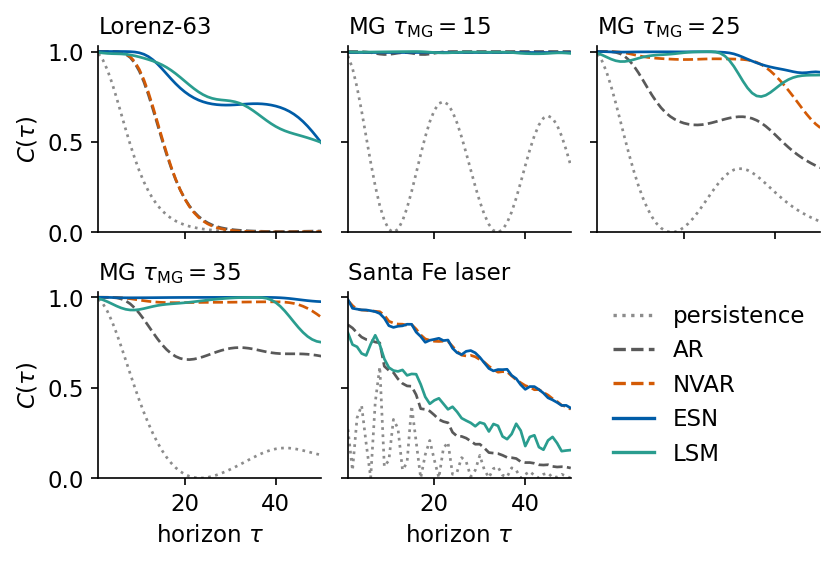

model           Lorenz      MG15      MG25      MG35   SantaFe     (test C_tot, maximum 50)
persistence        8.4      19.5      13.3      11.8       5.5
AR                15.4      49.8      33.1      38.0      16.5
NVAR              15.4      50.0      45.5      48.6      34.7
ESN               39.2      50.0      48.3      49.8      34.7
LSM               38.5      49.7      45.9      47.2      20.5

model           Lorenz      MG15      MG25      MG35   SantaFe     (tau_1/2, '>50' if C stays above 0.5)
persistence          8         6         8        10         1
AR                  16       >50        42       >50        16
NVAR                16       >50       >50       >50        42
ESN                 50       >50       >50       >50        40
LSM                 50       >50       >50       >50        18

one-step capacity C(1) of the LSM: Lorenz 0.995, MG15 0.998, MG25 0.991, MG35 0.993, SantaFe 0.803


In [19]:
MODELS = ("persistence", "AR", "NVAR", "ESN", "LSM")
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(2, 3, figsize=(5.5, 3.6), sharex=True, sharey=True)
    fig.subplots_adjust(left=0.11, right=0.985, bottom=0.13, top=0.93, wspace=0.12, hspace=0.32)
    for ax, name in zip(axs.ravel(), SIGNALS):
        for m in MODELS:
            ax.plot(TAUS, res[name][m]["C"], lw=1.3, label=m, **STYLE[m])
        ax.set_title(LABEL[name], loc="left", fontsize=11)
        ax.set_ylim(0, 1.03); ax.set_xlim(1, TAU_MAX)
    for ax in axs[1]: ax.set_xlabel(r"horizon $\tau$")
    for ax in axs[:, 0]: ax.set_ylabel(r"$C(\tau)$")
    axs[1, 2].axis("off")
    model_legend(axs[1, 2], MODELS, loc="center", handlelength=1.8)
    save(fig, "fig_lab048_capacity"); plt.show()

print(f"{'model':12s}" + "".join(f"{n:>10s}" for n in SIGNALS) + "     (test C_tot, maximum 50)")
for m in MODELS:
    print(f"{m:12s}" + "".join(f"{res[n][m]['Ctot']:10.1f}" for n in SIGNALS))
print(f"\n{'model':12s}" + "".join(f"{n:>10s}" for n in SIGNALS) + "     (tau_1/2, '>50' if C stays above 0.5)")
for m in MODELS:
    print(f"{m:12s}" + "".join(f"{(res[n][m]['tau_half'] or '>50'):>10}" for n in SIGNALS))
nums["Ctot"] = {n: {m: res[n][m]["Ctot"] for m in MODELS} for n in SIGNALS}
nums["tau_half"] = {n: {m: res[n][m]["tau_half"] for m in MODELS} for n in SIGNALS}
nums["lsm_C1"] = {n: float(res[n]["LSM"]["C"][0]) for n in SIGNALS}
print("\none-step capacity C(1) of the LSM: " + ", ".join(f"{n} {v:.3f}" for n, v in nums["lsm_C1"].items()))
nums["lsm_choice"] = {n: dict(zip(("J", "G", "tau_m", "tau_s", "beta"), res[n]["LSM"]["setting"]),
                              val_Ctot=res[n]["LSM"]["val_Ctot"]) for n in SIGNALS}
nums["esn_choice"] = {n: dict(zip(("rho", "sigma_in", "alpha", "beta"), res[n]["ESN"]["setting"])) for n in SIGNALS}

| test $C_{\rm tot}$ | Lorenz | MG 15 | MG 25 | MG 35 | Santa Fe |
|---|---|---|---|---|---|
| persistence | 8.4 | 19.5 | 13.3 | 11.8 | 5.5 |
| AR | 15.4 | 49.8 | 33.1 | 38.0 | 16.5 |
| NVAR | 15.4 | 50.0 | 45.5 | 48.6 | 34.7 |
| ESN, $N=300$ | 39.2 | 50.0 | 48.3 | 49.8 | 34.7 |
| LSM, $N=300$ | 38.5 | 49.7 | 45.9 | 47.2 | 20.5 |

The LSM with 300 neurons and an untrained random network forecasts the smooth signals well. On Lorenz it reaches $C_{\rm tot}=38.5$, more than twice the 15.4 of NVAR and 0.8 below the ESN, with a skill horizon of 50 horizons. On the Mackey–Glass signals it stays between 0.3 and 2.6 below the ESN, 0.4 above NVAR at $\tau_{\rm MG}=25$ and 1.4 below it at $\tau_{\rm MG}=35$. Its capacity curves on these signals show dips at intermediate horizons where the ESN curve stays flat. On Santa Fe the LSM reaches only 20.5, above AR (16.5) and far below NVAR and the ESN (34.7), and already its one-step capacity is 0.80, against at least 0.99 on the other four signals. The laser pulses change within one or two samples, and a neuron emits at most a few spikes in a sample of 10 ms, so the spike code resolves the fast pulsations coarsely. With the encoding $z_k=2s_k-1$ the input is negative most of the time, and 104 of the 300 neurons never fire on this signal at the illustration setting, which is a likely further cause. We did not test other encodings.

### Coupling, trace times and random draws

The selection is made on validation data, so the validation scores show which ingredients of the LSM matter. The left panel plots the best validation $C_{\rm tot}$ over all other settings as a function of the coupling $J$, and the right panel as a function of the largest trace time $\tau_s$, one line per signal. The coupling $J=0$ gives the best validation score on Lorenz, Mackey–Glass at 15, Mackey–Glass at 35 and Santa Fe, and on Santa Fe the score falls from 23.8 at $J=0$ to 19.8 at $J=0.03$. On Mackey–Glass at 25 the coupling $J=0.03$ is 0.014 above $J=0$, 45.481 against 45.467, and $J=0.01$ is 0.263 below. This difference is much smaller than the range of 0.6 of the test scores of five random networks on this signal, so there the couplings 0 and 0.03 are tied in this selection. The selected LSM is an uncoupled network, $J=0$, on Lorenz, Mackey–Glass at 15, Mackey–Glass at 35 and Santa Fe, and on these signals it is a set of 300 independent LIF neurons, each a nonlinear filter of the input with its own bias, input weight and trace time, with no synapse between them. On Mackey–Glass at 25 the selection chose $J=0.03$ by the small margin above. A likely explanation, supported by the scan of the echo state property but not tested directly, is that the recurrent synapses add irregular spikes and remove the locking to the input before they add useful features. The forecasting power would then come from the many neurons with different biases, input weights and trace times. The largest trace time matters more. On Lorenz the validation score grows from 34.6 at $\tau_s=100$ ms to 41.4 at 1000 ms, and on Mackey–Glass at 25 from 41.2 to 45.5 at 300 ms, while Santa Fe prefers the shortest value. These statements hold for this network of 300 neurons and these grids.

Lorenz   best validation C_tot by J: 0.0:  41.4, 0.01:  40.8, 0.03:  39.1 | by tau_s: 100.0:  34.6, 300.0:  39.8, 1000.0:  41.4
MG15     best validation C_tot by J: 0.0:  49.8, 0.01:  49.5, 0.03:  49.0 | by tau_s: 100.0:  49.3, 300.0:  49.7, 1000.0:  49.8
MG25     best validation C_tot by J: 0.0:  45.5, 0.01:  45.2, 0.03:  45.5 | by tau_s: 100.0:  41.2, 300.0:  45.5, 1000.0:  45.5
MG35     best validation C_tot by J: 0.0:  47.0, 0.01:  46.9, 0.03:  46.6 | by tau_s: 100.0:  43.6, 300.0:  47.0, 1000.0:  46.9
SantaFe  best validation C_tot by J: 0.0:  23.8, 0.01:  22.0, 0.03:  19.8 | by tau_s: 100.0:  23.8, 300.0:  23.2, 1000.0:  21.8
best validation C_tot by J, difference to J = 0 (three decimals):
Lorenz   J = 0: 41.408 (+0.000), J = 0.01: 40.812 (-0.595), J = 0.03: 39.114 (-2.294)
MG15     J = 0: 49.768 (+0.000), J = 0.01: 49.511 (-0.256), J = 0.03: 49.008 (-0.760)
MG25     J = 0: 45.467 (+0.000), J = 0.01: 45.205 (-0.263), J = 0.03: 45.481 (+0.014)
MG35     J = 0: 46.989 (+0.000), J =

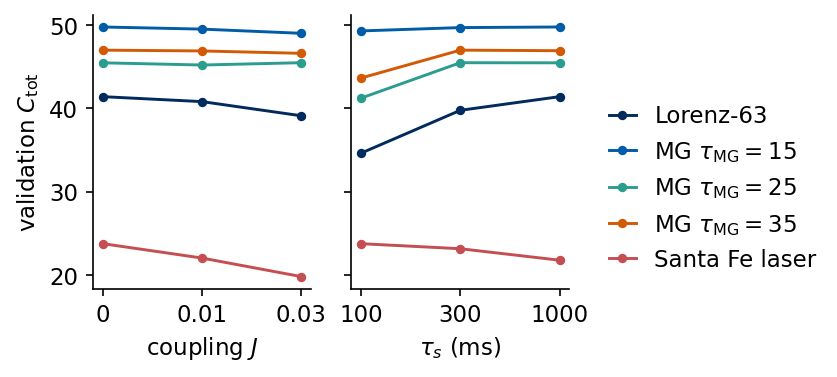

In [20]:
iJ = {J_: [i for i, g_ in enumerate(LSM_GRID) if g_[0] == J_] for J_ in (0.0, 0.01, 0.03)}
iT = {T_: [i for i, g_ in enumerate(LSM_GRID) if g_[3] == T_] for T_ in (100.0, 300.0, 1000.0)}
nums["scan"] = {n: dict(by_J={str(J_): float(res[n]["LSM"]["val_grid"][ix].max()) for J_, ix in iJ.items()},
                        by_tau_s={str(T_): float(res[n]["LSM"]["val_grid"][ix].max()) for T_, ix in iT.items()})
                for n in SIGNALS}
for n in SIGNALS:
    print(f"{n:8s} best validation C_tot by J: " + ", ".join(f"{k}: {v:5.1f}" for k, v in nums['scan'][n]['by_J'].items())
          + " | by tau_s: " + ", ".join(f"{k}: {v:5.1f}" for k, v in nums['scan'][n]['by_tau_s'].items()))
print("best validation C_tot by J, difference to J = 0 (three decimals):")
nums["scan_J_gap"] = {}
for n in SIGNALS:
    v = {J_: float(res[n]["LSM"]["val_grid"][ix].max()) for J_, ix in iJ.items()}
    nums["scan_J_gap"][n] = {str(J_): v[J_] - v[0.0] for J_ in v}
    print(f"{n:8s} " + ", ".join(f"J = {J_:g}: {v[J_]:.3f} ({v[J_] - v[0.0]:+.3f})" for J_ in v))
cols5 = dict(zip(SIGNALS, (UJNavy, UJBlue, Teal, DSOrange, "#C44E52")))
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.4), sharey=True, layout="constrained")
    for n in SIGNALS:
        axs[0].plot([0, 1, 2], list(nums["scan"][n]["by_J"].values()), "o-", ms=3.5, color=cols5[n], label=LABEL[n])
        axs[1].plot([0, 1, 2], list(nums["scan"][n]["by_tau_s"].values()), "o-", ms=3.5, color=cols5[n])
    axs[0].set_xticks([0, 1, 2], ["0", "0.01", "0.03"]); axs[0].set_xlabel("coupling $J$")
    axs[1].set_xticks([0, 1, 2], ["100", "300", "1000"]); axs[1].set_xlabel(r"$\tau_s$ (ms)")
    axs[0].set_ylabel(r"validation $C_{\rm tot}$")
    fig.legend(*axs[0].get_legend_handles_labels(), loc="outside right center", handlelength=1.2)
    save(fig, "fig_lab048_scan"); plt.show()

The spread of trace times is a design choice of ours, and we test it directly. At the selected setting of every signal we replace the log-uniform time constants by one common time constant for all neurons, either the selected $\tau_s$ or 30 ms, choose the ridge strength again on validation and compare the test $C_{\rm tot}$. We also check the echo state property at every selected setting, from two random initial voltages with the actual input, and repeat the selected setting with five networks drawn with different seeds.

In [21]:
nums["homog"], nums["esp_selected"], nums["seed_Ctot"] = {}, {}, {}
for name in SIGNALS:
    s = sig[name]; J_, G_, tm_, ts_, _ = res[name]["LSM"]["setting"]
    Yf, Yv, Yt = targets(s, K_FIT), targets(s, K_VAL), targets(s, K_TEST)
    TSh = np.vstack([np.full(N_LSM, ts_), np.full(N_LSM, 30.0)])
    Xh = lsm_features(net, 2 * s - 1, [(J_, G_, tm_, ts_)] * 2, TS=TSh)
    out = []
    for i in range(2):
        best = (-1, None)
        for beta, W, b in ridge_path(Xh[K_FIT, i], Yf, LSM_BETA):
            v = score(Xh[K_VAL, i] @ W + b, Yv)["Ctot"]
            if v > best[0]:
                best = (v, score(Xh[K_TEST, i] @ W + b, Yt)["Ctot"])
        out.append(best[1])
    nums["homog"][name] = dict(same_tau_s=out[0], tau30=out[1], spread=res[name]["LSM"]["Ctot"])
    # echo state property at the selected setting
    rng = np.random.default_rng(5)
    Xe = lsm_features(net, 2 * s - 1, [(J_, G_, tm_, ts_)] * 2, v0=rng.uniform(0, 1, (2, N_LSM)))
    d = np.linalg.norm(Xe[:, 0] - Xe[:, 1], axis=1) / np.linalg.norm(Xe[:, 0], axis=1).mean()
    nums["esp_selected"][name] = dict(d_first_fit=float(d[K_FIT[0]]), d_max_test=float(d[K_TEST].max()))
    # five random networks at the selected setting
    vals = []
    for sd in range(5):
        net_s = lsm_base(N_LSM, seed=sd)
        Xs = lsm_features(net_s, 2 * s - 1, [(J_, G_, tm_, ts_)])[:, 0]
        W, b = ridge_fit(Xs[K_FIT], Yf, res[name]["LSM"]["setting"][4])
        vals.append(score(Xs[K_TEST] @ W + b, Yt)["Ctot"])
    nums["seed_Ctot"][name] = vals
    print(f"{name:8s} test C_tot spread {res[name]['LSM']['Ctot']:5.1f} | one tau_s {out[0]:5.1f} | 30 ms {out[1]:5.1f}"
          f" || D at k = {K_FIT[0]}: {d[K_FIT[0]]:.1e}, max D on the test origins: {d[K_TEST].max():.1e}"
          f" || seeds: " + ", ".join(f"{v:5.1f}" for v in vals)
          + f" (range {max(vals) - min(vals):.1f}; ESN - LSM = {res[name]['ESN']['Ctot'] - res[name]['LSM']['Ctot']:.1f})")

Lorenz   test C_tot spread  38.5 | one tau_s  33.8 | 30 ms  21.1 || D at k = 63: 1.5e-03, max D on the test origins: 0.0e+00 || seeds:  38.5,  37.6,  38.6,  37.5,  37.4 (range 1.2; ESN - LSM = 0.8)


MG15     test C_tot spread  49.7 | one tau_s  47.1 | 30 ms  41.8 || D at k = 63: 1.2e-03, max D on the test origins: 0.0e+00 || seeds:  49.7,  49.7,  49.7,  49.7,  49.7 (range 0.1; ESN - LSM = 0.3)


MG25     test C_tot spread  45.9 | one tau_s  20.3 | 30 ms  20.6 || D at k = 63: 4.6e-02, max D on the test origins: 0.0e+00 || seeds:  45.9,  45.7,  45.9,  45.3,  45.4 (range 0.6; ESN - LSM = 2.4)


MG35     test C_tot spread  47.2 | one tau_s  25.6 | 30 ms  24.0 || D at k = 63: 8.7e-04, max D on the test origins: 0.0e+00 || seeds:  47.2,  47.2,  47.2,  47.2,  47.3 (range 0.2; ESN - LSM = 2.6)


SantaFe  test C_tot spread  20.5 | one tau_s  12.3 | 30 ms  13.1 || D at k = 63: 1.4e-06, max D on the test origins: 0.0e+00 || seeds:  20.5,  21.0,  20.8,  22.7,  20.9 (range 2.2; ESN - LSM = 14.2)


| test $C_{\rm tot}$ of the LSM | Lorenz | MG 15 | MG 25 | MG 35 | Santa Fe |
|---|---|---|---|---|---|
| spread of trace times, 5 ms to $\tau_s$ | 38.5 | 49.7 | 45.9 | 47.2 | 20.5 |
| one trace time $\tau_s$ | 33.8 | 47.1 | 20.3 | 25.6 | 12.3 |
| one trace time 30 ms | 21.1 | 41.8 | 20.6 | 24.0 | 13.1 |
| selected $\tau_s$ (ms) | 1000 | 1000 | 300 | 300 | 100 |
| five random networks, range | 37.4 to 38.6 | 49.7 to 49.7 | 45.3 to 45.9 | 47.2 to 47.3 | 20.5 to 22.7 |

With one common trace time the Mackey–Glass scores at 25 and 35 drop by more than 20 and the Lorenz score by 4.7. A single exponential filter gives every feature the same memory time, and the readout then cannot weight recent and older parts of the history differently. The spread of time constants has an effect similar to the range of relaxation rates of the eigenmodes of an ESN. At every selected setting the two copies of the network emit identical spike trains on all test origins, and the relative trace distance is zero there, so in this run the two copies agree on the test origins. At the first fitting origin, $k=63$, it is still up to $4.6\times10^{-2}$, on Mackey–Glass at 25. The five random networks give test values within 2.2 of each other on every signal. The difference between the ESN and the LSM exceeds this spread on Mackey–Glass at 15, Mackey–Glass at 25, Mackey–Glass at 35 and Santa Fe. On Lorenz it is 0.8, within the spread of 1.2 of the five LSM draws, so there the two reservoirs cannot be distinguished by these runs.

<hr/>
## 4. Surrogate gradients

The reservoir trains only a linear readout, so no derivative ever passes through a spike. Training the synaptic weights of a spiking network by gradient descent would need the derivative of the spike with respect to the voltage. The spike is a step function of the voltage, $S=\Theta(v-v_{\rm th})$, and its derivative $\delta(v-v_{\rm th})$ is zero for every voltage except the threshold, where it is infinite. The spike count of a neuron is therefore a staircase function of its input current and of every weight, and its exact gradient is zero almost everywhere. Backpropagation through a spiking network returns no information about which weight to change.

The surrogate-gradient method keeps the step function in the forward pass and replaces its derivative in the backward pass by a smooth peak of finite height [E. O. Neftci, H. Mostafa, F. Zenke, IEEE Signal Process. Mag. **36**, 51 (2019), [doi:10.1109/MSP.2019.2931595](https://doi.org/10.1109/MSP.2019.2931595)]. A common choice is the derivative of a fast sigmoid [F. Zenke, S. Ganguli, Neural Comput. **30**, 1514 (2018), [doi:10.1162/neco_a_01086](https://doi.org/10.1162/neco_a_01086)],
$$\frac{\partial S}{\partial v}\;\to\;\frac{1}{v_{\rm th}}\,\frac{1}{\big(1+\gamma_{\rm sg}|\zeta|\big)^2},\qquad \zeta=\frac{v-v_{\rm th}}{v_{\rm th}},$$
and another one is the derivative of the logistic function $1/(1+e^{-\gamma_{\rm sg}\zeta})$. The steepness $\gamma_{\rm sg}$ sets the width of the peak. The left panel shows the step function and the two surrogate derivatives for $\gamma_{\rm sg}=20$ in units of $1/v_{\rm th}$, with the logistic derivative normalised to the peak value 1 of the fast sigmoid. As a minimal illustration we compute the spike count $n(I_0)$ of the single LIF neuron of the first section ($t_{\rm ref}=0$) in a window of $T_{\rm w}=500$ ms as a function of a constant current and differentiate it with `jax.grad`. The middle panel shows the staircase $n(I_0)$ on a narrow range of currents above the rheobase, with the smooth curve $T_{\rm w}\nu(I_0)$ from the rate formula. The right panel compares the derivative of the smooth curve, $T_{\rm w}\,d\nu/dI_0$, with the surrogate gradient on the whole range.

exact gradient: max |dn/dI| = 0.0, surrogate vs T_w dnu/dI for I >= 0.2 nA: max relative deviation 0.11; mean surrogate below rheobase 196 per nA; jumps of n(I_0) on the zoomed range: 16


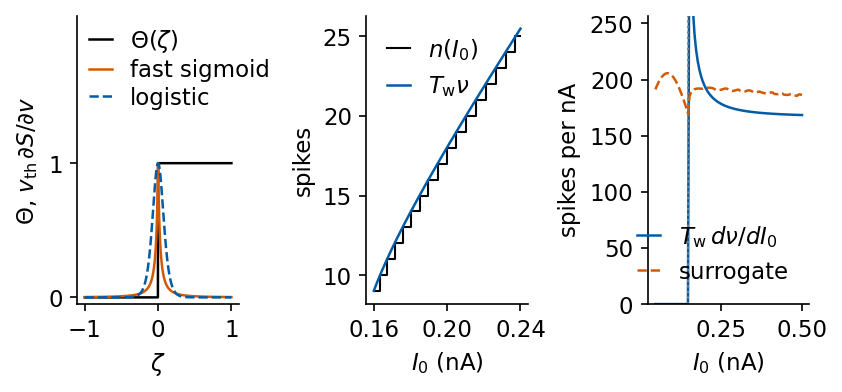

In [22]:
GAMMA_SG = 20.0

@jax.custom_jvp
def spike_sg(z):
    return (z >= 0).astype(z.dtype)                     # forward pass: step function
@spike_sg.defjvp
def _spike_sg_jvp(primals, tangents):
    (z,), (dz,) = primals, tangents
    return spike_sg(z), dz / (1.0 + GAMMA_SG * jnp.abs(z)) ** 2      # backward pass: fast-sigmoid derivative
spike_hard = lambda z: (z >= 0).astype(z.dtype)

T_SG = 500.0
def spike_count(I0, spike_fn):
    # LIF neuron without refractory time, Euler steps, reset v -> v (1 - S); returns the number of spikes in T_SG
    def step(v, _):
        v = v + DT1 / TAU_M * (-v + R_M * I0)
        S = spike_fn((v - V_TH) / V_TH)
        return v * (1.0 - S), S
    return jax.lax.scan(step, jnp.zeros(()), None, length=int(T_SG / DT1))[1].sum()

I_sg = jnp.linspace(0.05, 0.5, 91)
n_I = np.asarray(jax.vmap(lambda i: spike_count(i, spike_hard))(I_sg))
I_zoom = jnp.linspace(0.16, 0.24, 401)                      # narrow range above the rheobase for the staircase
n_zoom = np.asarray(jax.vmap(lambda i: spike_count(i, spike_hard))(I_zoom))
g_sg = np.asarray(jax.vmap(jax.grad(lambda i: spike_count(i, spike_sg)))(I_sg))
g_hard = np.asarray(jax.vmap(jax.grad(lambda i: spike_count(i, spike_hard)))(I_sg))
nu0 = lambda i: jnp.where(R_M * i > V_TH * (1 + 1e-9), 1.0 / (TAU_M * jnp.log(R_M * i / jnp.maximum(R_M * i - V_TH, 1e-12))), 0.0)
g_rate = np.asarray(jax.vmap(jax.grad(lambda i: T_SG * nu0(i)))(I_sg))
above = np.asarray(I_sg) >= 0.2
nums["sg"] = dict(beta=GAMMA_SG, gamma_sg=GAMMA_SG, exact_grad_max=float(np.abs(g_hard).max()), n_jumps_zoom=int((np.diff(n_zoom) != 0).sum()),
                  max_rel_dev_above=float(np.abs(g_sg[above] / g_rate[above] - 1).max()),
                  sg_below_rheobase=float(g_sg[np.asarray(I_sg) < 0.15].mean()))
print(f"exact gradient: max |dn/dI| = {np.abs(g_hard).max()}, surrogate vs T_w dnu/dI for I >= 0.2 nA:"
      f" max relative deviation {nums['sg']['max_rel_dev_above']:.2f}; mean surrogate below rheobase {nums['sg']['sg_below_rheobase']:.0f} per nA;"
      f" jumps of n(I_0) on the zoomed range: {nums['sg']['n_jumps_zoom']}")

with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 3, figsize=(5.5, 2.5), layout="constrained")
    z = np.linspace(-1, 1, 801)
    axs[0].plot(z, (z >= 0).astype(float), color="k", lw=1.2, label=r"$\Theta(\zeta)$")
    axs[0].plot(z, 1 / (1 + GAMMA_SG * np.abs(z)) ** 2, color=DSOrange, lw=1.2, label="fast sigmoid")
    sgm = 1 / (1 + np.exp(-GAMMA_SG * z))
    axs[0].plot(z, 4 * sgm * (1 - sgm), color=UJBlue, ls="--", lw=1.2, label="logistic")
    axs[0].set_xlabel(r"$\zeta$"); axs[0].set_ylabel(r"$\Theta$, $v_{\rm th}\,\partial S/\partial v$"); axs[0].legend(loc="upper left", handlelength=1.0, borderaxespad=0.1, labelspacing=0.2)
    axs[0].set_ylim(-0.05, 2.1); axs[0].set_yticks([0, 1])
    axs[1].step(np.asarray(I_zoom), n_zoom, where="post", color="k", lw=1.0, label="$n(I_0)$")
    axs[1].plot(np.asarray(I_zoom), T_SG * np.asarray(jax.vmap(nu0)(I_zoom)), color=UJBlue, lw=1.2, label=r"$T_{\rm w}\nu$")
    axs[1].set_xticks([0.16, 0.2, 0.24])
    axs[1].set_xlabel("$I_0$ (nA)"); axs[1].set_ylabel("spikes"); axs[1].legend(loc="upper left", handlelength=1.0)
    axs[2].plot(np.asarray(I_sg), g_rate, color=UJBlue, lw=1.2, label=r"$T_{\rm w}\,d\nu/dI_0$")
    axs[2].plot(np.asarray(I_sg), g_sg, color=DSOrange, ls="--", lw=1.2, label="surrogate")
    axs[2].axvline(V_TH / R_M, color="0.5", ls=":", lw=1.0)
    axs[2].set_xlabel("$I_0$ (nA)"); axs[2].set_ylabel("spikes per nA"); axs[2].set_ylim(0, 1.25 * g_sg.max())
    axs[2].legend(loc="lower right", handlelength=1.0)
    save(fig, "fig_lab048_surrogate"); plt.show()

The exact gradient through the step function is 0 at every current, since every step of the staircase is flat. Between its jumps the spike count does not change, and on the zoomed range it jumps 16 times by one spike. The surrogate gradient is positive everywhere. Below the rheobase the true spike count is zero and so is its slope, while the surrogate gradient has the mean value 196 spikes per nA there, because the surrogate responds to a voltage close to threshold whether or not the neuron fires. Above the rheobase it stays within 11% of $T_{\rm w}\,d\nu/dI_0$ for currents above 0.2 nA. For this neuron and this $\gamma_{\rm sg}$ the surrogate gives a gradient of the right sign and size where the neuron fires and a nonzero gradient where the true slope is zero. In general it is an approximation whose quality depends on $\gamma_{\rm sg}$ and on the network, and most gradient-trained spiking networks rely on it.

<hr/>
## Summary

The LIF neuron is an RC circuit with a threshold. Below threshold its voltage is the convolution of the input current with an exponential kernel of width $\tau_m$, an exponentially weighted history of the input, and one Euler step of the circuit has the form of the leaky ESN update with the leak rate $\alpha=\Delta t/\tau_m$. With threshold and reset the neuron fires above the rheobase at the rate $\nu(I_0)=1/\big(t_{\rm ref}+\tau_m\ln[RI_0/(RI_0-v_{\rm th})]\big)$, which our LIF implementation in JAX reproduces to 0.6%.

A liquid state machine of 300 such neurons with fixed random synapses and a ridge readout of exponentially filtered spike trains is a reservoir in the same sense as the ESN. Its echo state property depends on the regime of the neurons. With biases below threshold the spike times lock to the input, and in our finite runs two copies of the network become identical, while tonically firing neurons and strong coupling keep a memory of the initial state. The spiking reservoir recovers only 3.0 past values of a white-noise input with 300 neurons, against 44.1 for an ESN of the same size, but it forecasts the smooth signals with test capacities close to the ESN, 38.5 against 39.2 on Lorenz and 45.9 against 48.3 on Mackey–Glass at 25, when the trace time constants are spread log-uniformly from 5 ms to the selected $\tau_s$ of 300 or 1000 ms. On the Santa Fe laser it stays far below the ESN. On four of the five signals the selected network has no coupling at all and is a set of independent LIF filters, so the useful features came from the heterogeneous single neurons. All numbers refer to one network size, these grids, these signals and an input held for 10 ms per sample.

Training the synapses of a spiking network by gradient descent fails with the exact derivative of the threshold, which is zero almost everywhere. Surrogate gradients replace it by a smooth peak, and for a single LIF neuron the surrogate derivative of the spike count has the size of the slope of the rate curve where the neuron fires. The reservoir needs no derivative through a spike at all, because only the linear readout is trained.